# Modelo de compra (Fase 1), criterio *equilibrado*, con la restricción (4) manejada explícitamente

Para cada polígono $p$ se maximiza la **cobertura mínima** entre especies, $\min_e\big(1-\mathbb{E}[F_{e,p}]/D_{e,p}\big)$, con $F_{e,p}=\max\{0,D_{e,p}-X_{e,p}-Z_{e,p}\}$, sujeto a

$$\sum_e c_e(q^I_{e,p}+q^R_{e,p})\le B A_p\ (3),\quad \sum_e q^I_{e,p}\le \mathbb{E}[L_p]\ (4),\quad q^I_{e,p}\le \max\{0,(1+\delta)D_{e,p}-\mathbb{E}[X_{e,p}]\}\ (5),\quad q^R_{e,p}\le q^I_{e,p}\ (6).$$

$X$: modelo B, Bin$(x,0.95)$. $Z$: secuencial con $S_e$ a 2 años. Números aleatorios comunes (un flujo de Bernoulli por planta).

**Cómo se maneja (4).** Es una restricción de tope normal: el algoritmo (voraz) compra de una en una la unidad con mayor beneficio por peso gastado. Cada siembra consume un punto de la malla y, cuando ya no quedan puntos disponibles ($\sum_e q^I_{e,p}=\mathbb{E}[L_p]$), solo se permiten reposiciones (que no usan puntos, pero sí requieren siembras previas por la restricción (6)). El presupuesto (3) se maneja igual: se compra mientras alcance.

**Cotas.** Cada planta comprada aporta a lo más $S_e$ plantas establecidas en esperanza, lo que da una cota de cobertura mínima que solo usa el presupuesto. Si además se exige $\sum q^I\le L_p$ y $q^R\le(1-S_e)q^I$ en esperanza, la cota se calcula con un LP por polígono (`cota_lp`). Sirven para saber cuánto se puede mejorar como máximo.

**Flujo completo del notebook.** (1) La compra decide *cuántas* plantas de cada especie se siembran y reponen en cada polígono (secciones 1–4). (2) El acomodo decide *dónde* va cada una: para cada polígono se construye una plantilla de tres bolillo de 14 × 47 posiciones con la composición de lo que se compró, y se ordena para minimizar la competencia entre vecinas (sección 5). (3) La plantilla se lleva a la geometría real de cada polígono y se corrigen los conteos para que coincidan exactamente con la compra (sección 6). (4) Se compara contra la opción más práctica en campo: repetir una sola plantilla en todo el terreno, sin corregir nada (sección 7).

## 0. Configuración y datos

In [1]:
import os, time, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.optimize import linprog
from scipy.spatial import cKDTree
import numba
import geopandas as gpd, shapely
from shapely import affinity

plt.rcParams.update({'font.size': 11})

# ---------------- CONFIGURACIÓN ----------------
N_OPT, N_VAL, SEED = 10_000, 20_000, 2026
ERR_REG = 0.05            # modelo B
DELTA   = 0.05            # restricción (5)
PREF_R  = 0.99            # desempate: a igualdad se prefiere sembrar antes que reponer
SUPERV  = 'sobrev_2023'

datos = pd.read_csv('datos/especies y poligonos/datos_limpios.csv')
par   = pd.read_csv('datos/especies y poligonos/parametros_especies.csv').set_index('especie')
esp   = list(par.index)
x     = datos.pivot(index='especie', columns='poligono', values='plantas').loc[esp]
A     = datos.drop_duplicates('poligono').set_index('poligono')['area_ha'].sort_index()
x     = x[A.index]
E_, P_ = x.shape
d = par['meta_plantas_ha'].values.astype(float); c = par['costo_c'].values.astype(float); S = par[SUPERV].values.astype(float)
D = np.outer(d, A.values)

def simular_X(n, rng):
    return rng.binomial(x.values, 1 - ERR_REG, size=(n, E_, P_))

X   = simular_X(N_OPT, np.random.default_rng(SEED))
EXm = X.mean(0)
print('X:', X.shape, '| meta total:', f'{D.sum():,.0f}', 'plantas | área total:', round(A.sum(), 1), 'ha')

X: (10000, 10, 30) | meta total: 120,421 plantas | área total: 183.0 ha


## 1. Optimizador por polígono y cotas

In [2]:
def optimizar_poligono(p, X, rng, B_ha, ptos_ha, delta=DELTA):
    """Criterio equilibrado para el polígono p (0-based)."""
    n = X.shape[0]; idx = np.arange(n)
    EX    = X[:, :, p].mean(0)
    Np_p  = int(round(ptos_ha * A.values[p]))
    L     = np.maximum(Np_p - X[:, :, p].sum(1), 0)
    slots = int(np.floor(L.mean()))                                           # restricción (4): puntos de malla disponibles
    U     = np.maximum(0, np.floor((1 + delta) * D[:, p] - EX)).astype(int)   # restricción (5)
    budget = B_ha * A.values[p]                                               # restricción (3)

    B1 = [(rng.random((U[e], n)) < S[e]).astype(np.int8) for e in range(E_)]
    C2 = [np.vstack([np.zeros((1, n), np.int16),
                     np.cumsum(rng.random((U[e], n)) < S[e], axis=0, dtype=np.int16)]) for e in range(E_)]
    qI = np.zeros(E_, int); qR = np.zeros(E_, int)
    ZI = np.zeros((E_, n), np.int32); dead = np.zeros((E_, n), np.int32)
    Fm = np.maximum(0.0, D[:, p, None] - X[:, :, p].T).mean(1)

    def candidatos(e):
        out = [-np.inf, -np.inf]; new = [None, None]
        if qI[e] < U[e]:                                                       # +1 siembra
            zi = ZI[e] + B1[e][qI[e]]; dd = (qI[e] + 1) - zi
            zr = C2[e][np.minimum(qR[e], dd), idx]
            F2 = np.maximum(0.0, D[e, p] - X[:, e, p] - zi - zr)
            out[0] = (Fm[e] - F2.mean()) / c[e]; new[0] = (zi, dd, F2)
        if qR[e] < qI[e]:                                                      # +1 reposición (restricción 6)
            zr = C2[e][np.minimum(qR[e] + 1, dead[e]), idx]
            F2 = np.maximum(0.0, D[e, p] - X[:, e, p] - ZI[e] - zr)
            out[1] = PREF_R * (Fm[e] - F2.mean()) / c[e]; new[1] = (ZI[e], dead[e], F2)
        return out, new

    sc = np.full((E_, 2), -np.inf); nw = [[None, None] for _ in range(E_)]
    for e in range(E_): sc[e], nw[e] = candidatos(e)
    left, slots_left = budget, slots
    while True:
        ok = sc.max(1) > 1e-12
        if not ok.any(): break
        cob = np.where(ok, 1 - Fm / D[:, p], np.inf)                           # cobertura actual por especie
        e = int(np.argmin(cob)); t = int(np.argmax(sc[e]))
        if c[e] > left:                sc[e] = -np.inf; continue
        if t == 0 and slots_left <= 0: sc[e, 0] = -np.inf; continue
        zi, dd, F2 = nw[e][t]
        if t == 0: qI[e] += 1; slots_left -= 1
        else:      qR[e] += 1
        ZI[e], dead[e] = zi, dd; Fm[e] = F2.mean(); left -= c[e]
        sc[e], nw[e] = candidatos(e)
    return qI, qR, dict(gasto=budget - left, presupuesto=budget, slots=slots - slots_left, slots_disp=slots, EF=Fm.copy())

def cota_presupuesto(p, B_ha):
    """Cobertura mínima máxima con solo el presupuesto (cada planta aporta a lo más S_e en esperanza)."""
    return (B_ha * A.values[p] + (c * EXm[:, p] / S).sum()) / (c * D[:, p] / S).sum()

def cota_lp(p, B_ha, ptos_ha):
    """Cota con presupuesto y puntos de malla: siembras >= Q_e/(2-S_e) (reposición <= (1-S_e)*siembras)."""
    L = ptos_ha * A.values[p] - EXm[:, p].sum()
    cv = np.zeros(E_ + 1); cv[-1] = -1
    Au = [np.r_[c, 0], np.r_[1 / (2 - S), 0]]; bu = [B_ha * A.values[p], L]
    for e in range(E_):
        r = np.zeros(E_ + 1); r[e] = -S[e]; r[-1] = D[e, p]; Au.append(r); bu.append(EXm[e, p])
    res = linprog(cv, A_ub=np.array(Au), b_ub=np.array(bu), bounds=[(0, None)] * E_ + [(0, 1)], method='highs')
    return -res.fun

def resolver_todos(X, B_ha, ptos_ha):
    QI = np.zeros((E_, P_), int); QR = np.zeros((E_, P_), int); infos = []
    for p in range(P_):
        qi, qr, info = optimizar_poligono(p, X, np.random.default_rng(1000 + p), B_ha, ptos_ha)
        QI[:, p], QR[:, p] = qi, qr; infos.append(info)
    return QI, QR, infos

## 2. Escenarios y validación fuera de muestra
20,000 escenarios nuevos de $X$ y $Z$ (simulación directa).

In [3]:
def validar(QI, QR, n=N_VAL, seed=99):
    r = np.random.default_rng(seed); Xv = simular_X(n, r)
    ZI = r.binomial(QI, S[:, None], size=(n, E_, P_)); ZR = r.binomial(np.minimum(QR, QI - ZI), S[:, None])
    Z = ZI + ZR; return Xv, Z, np.maximum(0.0, D - Xv - Z)

def resumen(QI, QR):
    Xv, Z, F = validar(QI, QR)
    t = pd.DataFrame({'meta': D.sum(1), 'E_X': Xv.mean(0).sum(1), 'E_Z': Z.mean(0).sum(1), 'E_F': F.mean(0).sum(1),
                      'q_siembra': QI.sum(1), 'q_reposicion': QR.sum(1), 'gasto': (c[:, None] * (QI + QR)).sum(1)}, index=esp)
    t['cobertura_%'] = 100 * (1 - t.E_F / t.meta)
    return t

escenarios = [('A', 12_500, 658), ('B', 13_200, 658), ('C', 13_200, 600)]
resultados, filas = {}, []
for nombre, B_ha, ptos in escenarios:
    t0 = time.time(); QI, QR, infos = resolver_todos(X, B_ha, ptos)
    t = resumen(QI, QR); resultados[nombre] = (B_ha, ptos, QI, QR, t)
    cota = np.average([cota_lp(p, B_ha, ptos) for p in range(P_)], weights=D.sum(0))
    filas.append((nombre, B_ha, ptos, time.time() - t0,
                  t.E_F.sum(), 100 * t.E_F.sum() / t.meta.sum(), t['cobertura_%'].min(), 100 * cota,
                  t.gasto.sum(), B_ha * A.sum(), sum(i['slots'] for i in infos), sum(i['slots_disp'] for i in infos)))
    print(f'{nombre}: {time.time()-t0:.0f} s', flush=True)
comp = pd.DataFrame(filas, columns=['esc', 'presup_ha', 'puntos_ha', 'seg', 'faltante_esperado', 'faltante_%',
                                    'cobertura_min_%', 'cota_LP_%', 'gasto', 'presupuesto', 'puntos_usados', 'puntos_disp']).set_index('esc')
comp.round({'seg': 0, 'faltante_esperado': 0, 'faltante_%': 2, 'cobertura_min_%': 2, 'cota_LP_%': 2, 'gasto': 0, 'presupuesto': 0})

A: 42 s


B: 43 s


C: 42 s


,presup_ha,puntos_ha,seg,faltante_esperado,faltante_%,cobertura_min_%,cota_LP_%,gasto,presupuesto,puntos_usados,puntos_disp
esc,,,,,,,,,,,
A,12500,658,42.0,14435.0,11.99,87.94,88.02,2287364.0,2287625.0,95624,98017
B,13200,658,43.0,9751.0,8.10,91.83,91.91,2415544.0,2415732.0,98017,98017
C,13200,600,42.0,13316.0,11.06,86.23,89.58,2415540.0,2415732.0,87404,87404


`A` y `B` usan 658 puntos/ha (placeholder); `C` usa una malla más ajustada de 600 puntos/ha, donde la restricción (4) sí limita. La cobertura mínima está en la validación fuera de muestra, y la cota LP es el máximo alcanzable en esperanza (promedio ponderado por meta de los polígonos).

,A,B,C
Agave lechuguilla,88.1,92.0,86.2
Agave salmiana,87.9,91.8,87.2
Agave scabra,88.1,91.9,91.9
Agave striata,88.1,92.0,86.9
Opuntia cantabrigiensis,88.1,92.0,91.0
Opuntia engelmannii,88.1,92.0,91.0
Opuntia robusta,88.0,91.9,86.5
Opuntia streptacantha,88.0,91.9,90.4
Prosopis laevigata,88.0,91.9,91.8
Yucca filifera,88.1,92.0,92.0


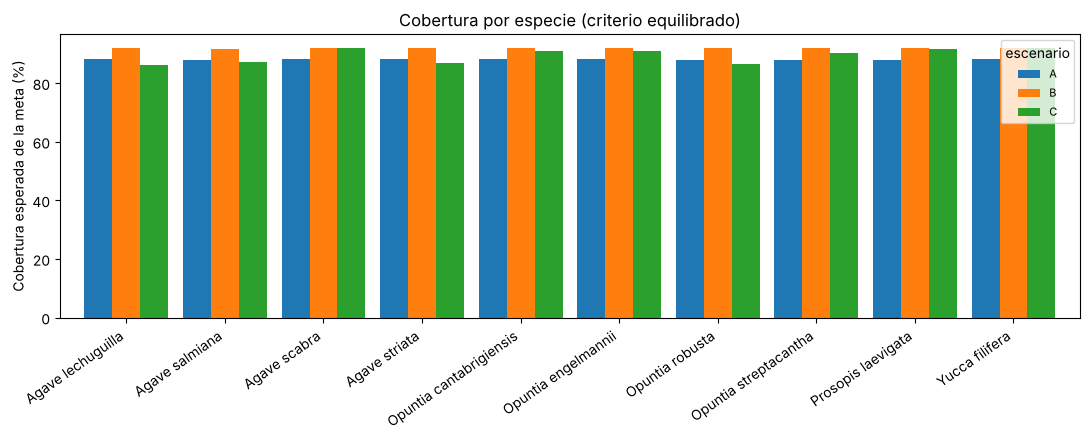

In [4]:
cob = pd.DataFrame({k: v[4]['cobertura_%'] for k, v in resultados.items()}).round(1)
display(cob)
ax = cob.plot.bar(figsize=(11, 4.5), width=0.85); ax.set_ylabel('Cobertura esperada de la meta (%)'); ax.set_xlabel('')
ax.set_title('Cobertura por especie (criterio equilibrado)'); plt.xticks(rotation=35, ha='right'); plt.legend(title='escenario', fontsize=8)
plt.tight_layout(); plt.show()

## 3. Reasignación del remanente de presupuesto
Se junta lo que sobra en todos los polígonos (presupuesto − gasto) y se gasta de una en una en la unidad (siembra o reposición) con mayor beneficio por peso, empezando por el par (polígono, especie) de menor cobertura. Se respetan (4), (5) y (6) en cada polígono; el presupuesto (3) se cumple en el total (el remanente se mueve entre polígonos).

Usa los mismos números aleatorios (misma semilla y orden de sorteos) que `optimizar_poligono`, así que continúa exactamente desde el estado en que quedó el optimizador. Con `ACTUALIZAR_RESULTADOS = True` se reemplaza `resultados`, de modo que la sección 4 y lo que sigue usan el plan ajustado.

In [5]:
ACTUALIZAR_RESULTADOS = True      # True: reemplaza `resultados` (la sección 4 y lo que sigue usan el plan ajustado)
MAX_CACHE = 4                     # polígonos que se mantienen en memoria a la vez

if 'resultados_base' not in globals():            # copia del resultado original: la celda se puede correr varias veces
    resultados_base = dict(resultados)

def estado_poligono(p, QI, QR, ptos_ha):
    """Reconstruye el estado del polígono p tras las compras (QI, QR), con los mismos sorteos que optimizar_poligono."""
    n = X.shape[0]; idx = np.arange(n); rng = np.random.default_rng(1000 + p)
    EX    = X[:, :, p].mean(0)
    L     = np.maximum(int(round(ptos_ha * A.values[p])) - X[:, :, p].sum(1), 0)
    U     = np.maximum(0, np.floor((1 + DELTA) * D[:, p] - EX)).astype(int)
    B1 = [(rng.random((U[e], n)) < S[e]).astype(np.int8) for e in range(E_)]
    C2 = [np.vstack([np.zeros((1, n), np.int16),
                     np.cumsum(rng.random((U[e], n)) < S[e], axis=0, dtype=np.int16)]) for e in range(E_)]
    ZI = np.zeros((E_, n), np.int32); dead = np.zeros((E_, n), np.int32); Fm = np.zeros(E_)
    for e in range(E_):
        ZI[e]   = B1[e][:QI[e, p]].sum(0)
        dead[e] = QI[e, p] - ZI[e]
        zr = C2[e][np.minimum(QR[e, p], dead[e]), idx]
        Fm[e] = np.maximum(0.0, D[e, p] - X[:, e, p] - ZI[e] - zr).mean()
    return dict(U=U, B1=B1, C2=C2, ZI=ZI, dead=dead, Fm=Fm, slots=int(np.floor(L.mean())))

def reasignar_remanente(nombre):
    B_ha, ptos, QI0, QR0, _ = resultados_base[nombre]
    QI, QR = QI0.copy(), QR0.copy()
    idx = np.arange(X.shape[0])
    sobrante_pol = B_ha * A.values - (c[:, None] * (QI + QR)).sum(0)
    R0 = R = float(sobrante_pol.sum())                                   # remanente total, sumado entre polígonos

    # Estado inicial de cada polígono (solo se guarda lo ligero; los flujos aleatorios se regeneran al necesitarlos)
    Fm = np.zeros((E_, P_)); slots_left = np.zeros(P_, int)
    for p in range(P_):
        st = estado_poligono(p, QI, QR, ptos)
        Fm[:, p] = st['Fm']; slots_left[p] = st['slots'] - QI[:, p].sum()
    Fm_ini = Fm.copy(); cob_ini = 1 - Fm / D

    cache = {}
    def obtener(p):
        if p not in cache:
            if len(cache) >= MAX_CACHE: cache.pop(next(iter(cache)))
            cache[p] = estado_poligono(p, QI, QR, ptos)
        return cache[p]

    vivo = np.ones((E_, P_), bool)                                       # pares (especie, polígono) que aún pueden recibir compras
    while True:
        cob = 1 - Fm / D
        cand = np.where(vivo, cob, np.inf)
        if not np.isfinite(cand).any(): break
        e, p = np.unravel_index(np.argmin(cand), cand.shape); e, p = int(e), int(p)
        if c[e] > R + 1e-9:                                              # la especie ya no alcanza en ningún polígono
            vivo[e, :] = False; continue
        st = obtener(p); U, B1, C2, ZI, dead = st['U'], st['B1'], st['C2'], st['ZI'], st['dead']
        opc = [(-np.inf, None), (-np.inf, None)]
        if QI[e, p] < U[e] and slots_left[p] > 0:                        # +1 siembra: restricciones (5) y (4)
            zi = ZI[e] + B1[e][QI[e, p]]; dd = (QI[e, p] + 1) - zi
            zr = C2[e][np.minimum(QR[e, p], dd), idx]
            F2 = np.maximum(0.0, D[e, p] - X[:, e, p] - zi - zr)
            opc[0] = ((Fm[e, p] - F2.mean()) / c[e], (zi, dd, F2))
        if QR[e, p] < QI[e, p]:                                          # +1 reposición: restricción (6)
            zr = C2[e][np.minimum(QR[e, p] + 1, dead[e]), idx]
            F2 = np.maximum(0.0, D[e, p] - X[:, e, p] - ZI[e] - zr)
            opc[1] = (PREF_R * (Fm[e, p] - F2.mean()) / c[e], (ZI[e], dead[e], F2))
        t = int(np.argmax([opc[0][0], opc[1][0]]))
        if opc[t][0] <= 1e-12:                                           # sin beneficio o sin opciones: se descarta el par
            vivo[e, p] = False; continue
        zi, dd, F2 = opc[t][1]
        if t == 0: QI[e, p] += 1; slots_left[p] -= 1
        else:      QR[e, p] += 1
        ZI[e], dead[e] = zi, dd; Fm[e, p] = F2.mean(); R -= c[e]

    # ---------- Verificaciones ----------
    U_all = np.maximum(0, np.floor((1 + DELTA) * D - EXm)).astype(int)
    assert (QI <= U_all).all() and (QR <= QI).all(), 'se violó (5) o (6)'
    assert (slots_left >= 0).all(), 'se violó (4)'
    assert (c[:, None] * (QI + QR)).sum() <= (B_ha * A.values).sum() + 1e-6, 'se excedió el presupuesto total'
    assert (QI >= QI0).all() and (QR >= QR0).all(), 'no se debe quitar nada del plan original'
    return QI, QR, dict(B_ha=B_ha, ptos=ptos, R0=R0, R=R, sobrante_pol=sobrante_pol, Fm_ini=Fm_ini, Fm=Fm.copy(),
                        dQI=QI - QI0, dQR=QR - QR0)

# ---------- Ejecución en los tres escenarios ----------
resultados_ajustados, filas_rem, detalle = {}, [], []
for nombre in resultados_base:
    t0 = time.time()
    B_ha, ptos, QI0, QR0, t0_ = resultados_base[nombre]
    QI2, QR2, info = reasignar_remanente(nombre)
    t2 = resumen(QI2, QR2); resultados_ajustados[nombre] = (B_ha, ptos, QI2, QR2, t2)

    # Cobertura por polígono (mínima entre especies), validación fuera de muestra con los mismos escenarios antes y después
    _, _, F0 = validar(QI0, QR0); _, _, F1 = validar(QI2, QR2)
    cp0 = (1 - F0.mean(0) / D).min(0); cp1 = (1 - F1.mean(0) / D).min(0)
    filas_rem.append((nombre, info['R0'], info['R'], int(info['dQI'].sum()), int(info['dQR'].sum()),
                      100 * t0_.E_F.sum() / t0_.meta.sum(), 100 * t2.E_F.sum() / t2.meta.sum(),
                      t0_.E_F.sum() - t2.E_F.sum(), 100 * cp0.min(), 100 * cp1.min(), time.time() - t0))
    for p in np.where((info['dQI'] + info['dQR']).sum(0) > 0)[0]:
        for e in np.where(info['dQI'][:, p] + info['dQR'][:, p] > 0)[0]:
            detalle.append((nombre, A.index[p], esp[e], info['dQI'][e, p], info['dQR'][e, p],
                            c[e] * (info['dQI'][e, p] + info['dQR'][e, p]),
                            100 * (1 - info['Fm_ini'][e, p] / D[e, p]), 100 * (1 - info['Fm'][e, p] / D[e, p]),
                            100 * cp0[p], 100 * cp1[p]))
    if ACTUALIZAR_RESULTADOS: resultados[nombre] = resultados_ajustados[nombre]
    print(f'{nombre}: {time.time()-t0:.0f} s', flush=True)

rem = pd.DataFrame(filas_rem, columns=['esc', 'remanente_inicial', 'remanente_final', '+siembras', '+reposiciones',
                                       'faltante_%_antes', 'faltante_%_despues', 'faltante_plantas_menos',
                                       'cob_min_pol_%_antes', 'cob_min_pol_%_despues', 'seg']).set_index('esc')
display(rem.round({'remanente_inicial': 2, 'remanente_final': 2, 'faltante_%_antes': 3, 'faltante_%_despues': 3,
                   'faltante_plantas_menos': 1, 'cob_min_pol_%_antes': 2, 'cob_min_pol_%_despues': 2, 'seg': 0}))
det = pd.DataFrame(detalle, columns=['esc', 'poligono', 'especie', '+siembra', '+reposicion', 'costo',
                                     'cob_especie_%_antes', 'cob_especie_%_despues',
                                     'cob_pol_%_antes(valid.)', 'cob_pol_%_despues(valid.)'])
display(det.round(2))
print('resultados actualizados con el remanente' if ACTUALIZAR_RESULTADOS else 'resultados NO actualizados (ver resultados_ajustados)')


A: 17 s


B: 17 s


C: 61 s


,remanente_inicial,remanente_final,+siembras,+reposiciones,faltante_%_antes,faltante_%_despues,faltante_plantas_menos,cob_min_pol_%_antes,cob_min_pol_%_despues,seg
esc,,,,,,,,,,
A,261.0,16.0,8,2,11.987,11.980,8.0,86.89,87.1,17.0
B,188.0,8.5,0,8,8.097,8.092,6.8,90.77,91.0,17.0
C,191.5,11.5,0,8,11.058,11.054,5.0,85.10,85.1,61.0


,esc,poligono,especie,+siembra,+reposicion,costo,cob_especie_%_antes,cob_especie_%_despues,cob_pol_%_antes(valid.),cob_pol_%_despues(valid.)
0,A,18,Agave lechuguilla,1,0,26.0,87.06,87.47,86.89,87.14
1,A,18,Agave salmiana,3,0,78.0,86.94,87.20,86.89,87.14
2,A,18,Opuntia cantabrigiensis,1,0,18.0,87.12,87.44,86.89,87.14
3,A,18,Opuntia robusta,1,0,18.0,86.97,87.20,86.89,87.14
4,A,18,Prosopis laevigata,2,0,53.0,86.91,87.26,86.89,87.14
5,A,18,Yucca filifera,0,1,26.0,87.05,87.56,86.89,87.14
6,A,23,Yucca filifera,0,1,26.0,87.11,87.47,87.05,87.13
7,B,18,Agave salmiana,0,2,52.0,90.80,90.97,90.77,91.00
8,B,18,Agave scabra,0,1,26.0,90.83,91.16,90.77,91.00
9,B,18,Opuntia cantabrigiensis,0,1,18.0,90.87,91.19,90.77,91.00


resultados actualizados con el remanente


## 4. Plan de compra por polígono y especie

In [6]:
filas = []
for nombre in ('A', 'B', 'C'):
    B_ha, ptos, QI, QR, _ = resultados[nombre]
    for j, pol in enumerate(A.index):
        for i, e in enumerate(esp):
            filas.append((nombre, B_ha, ptos, pol, A.values[j], e, QI[i, j], QR[i, j], QI[i, j] + QR[i, j], c[i] * (QI[i, j] + QR[i, j])))
plan = pd.DataFrame(filas, columns=['escenario', 'presupuesto_ha', 'puntos_malla_ha', 'poligono', 'area_ha', 'especie',
                                    'q_siembra', 'q_reposicion', 'q_total', 'costo'])
plan.to_csv('plan_compra_equilibrado.csv', index=False); print(plan.shape)
plan.query("escenario == 'B' and poligono == 1")

(900, 10)


,escenario,presupuesto_ha,puntos_malla_ha,poligono,area_ha,especie,q_siembra,q_reposicion,q_total,costo
300,B,13200,658,1,1.28,Agave lechuguilla,44,2,46,1196.0
301,B,13200,658,1,1.28,Agave salmiana,200,6,206,5356.0
302,B,13200,658,1,1.28,Agave scabra,41,5,46,1196.0
303,B,13200,658,1,1.28,Agave striata,37,1,38,988.0
304,B,13200,658,1,1.28,Opuntia cantabrigiensis,55,2,57,1026.0
305,B,13200,658,1,1.28,Opuntia engelmannii,37,2,39,819.0
306,B,13200,658,1,1.28,Opuntia robusta,72,3,75,1350.0
307,B,13200,658,1,1.28,Opuntia streptacantha,72,3,75,1350.0
308,B,13200,658,1,1.28,Prosopis laevigata,101,5,106,2809.0
309,B,13200,658,1,1.28,Yucca filifera,26,5,31,806.0


## 5. Acomodo: de la compra a una plantilla por polígono

**Idea.** El modelo de compra fija las cantidades; el acomodo solo las distribuye en el espacio. Así los dos modelos se comunican en un solo sentido y sin contradicciones: el QAP ya no elige cuántas plantas de cada especie hay (no hay $\delta$), y la compra ya no necesita topes por especie derivados de una plantilla.

**Bloque de 14 × 47 = 658 posiciones.** Las metas del plan son enteras y suman 658 plantas/ha, así que el bloque equivale a una hectárea de meta y la plantilla del plan reproduce las proporciones **exactamente** ($w_e = d_e$). Tiene número par de filas, como pide el tres bolillo con bordes periódicos.

**Plantilla de cada polígono $p$.** Sus conteos son proporcionales a lo que realmente hay que sembrar ahí:

$$w_{e,p} \propto q^I_{e,p}\quad (e=1,\dots,10),\qquad w_{\varnothing,p}\propto \max\{0,\ \mathbb{E}[L_p]-\textstyle\sum_e q^I_{e,p}\},$$

redondeados a 658 posiciones por restos mayores. La clase $\varnothing$ ("vacío") representa los puntos libres que no se van a sembrar (cuando el presupuesto, y no la malla, es lo que limita); su competencia con cualquier especie es 0, así que el recocido los usa para separar a las especies que más compiten.

**Regla en campo.** La cuadrilla recorre la malla del polígono; en el punto (fila $r$, columna $k$) consulta la posición $((r-1)\bmod 14+1,\ (k-1)\bmod 47+1)$ de la plantilla de su polígono. Si ya hay una planta viva, se salta el punto; si no, siembra la especie indicada (o lo deja vacío). Las reposiciones $q^R$ van en el mismo punto de la planta que murió, con la misma especie, así que no usan posiciones nuevas.

**Supuestos.** (i) No se conoce la ubicación de las plantas existentes, así que el acomodo ignora la competencia con ellas; como se saltan al azar, en esperanza cada especie pierde la misma fracción de posiciones y los conteos sembrados quedan proporcionales a $q^I_{e,p}$. (ii) Un bloque pequeño repetido representa bien al polígono completo: con la matriz de ejemplo, la reducción de competencia fue de 24.1 % con un bloque de 1,316 posiciones y de 24.3 % con uno de 4,250, así que no vale la pena resolver mapas de miles de posiciones. Con 658 posiciones la plantilla es más fácil de seguir en campo; el costo es que, con bordes periódicos de solo 14 filas, cada posición tiene menos vecinas "lejanas" distintas.

> **Importante:** si existe `Competencia.xlsx` (10 × 10, especies en encabezado e índice) se usa; si no, se genera una matriz **de ejemplo** para que el código corra. Los resultados de competencia solo son válidos con la $C_{ij}$ real.

**¿Es óptimo?** El recocido simulado no garantiza el óptimo global, así que a su resultado lo llamamos *acomodo optimizado* (mejor encontrado). Para saber qué tan lejos puede estar del óptimo se calcula una **cota inferior** de $Z$: en la malla de tres bolillo cada arista pertenece exactamente a 2 triángulos y cada posición a 6, así que, si $y_T$ es el número de triángulos cuyas tres especies forman el multiconjunto $T$,

$$Z=\tfrac12\sum_T c_T\,y_T,\qquad c_T=C_{ij}+C_{jk}+C_{ik},\qquad \sum_T m_e(T)\,y_T = 6\,w_e\ \ \forall e,\quad y_T\ge 0,$$

donde $m_e(T)$ es cuántas veces aparece la especie $e$ en $T$. El mínimo de este problema lineal (220 variables) es una cota inferior de $Z$ para cualquier acomodo con conteos $w$; la **brecha** $Z/\text{cota}-1$ acota qué tan lejos del óptimo está la solución.

**Mejoras al recocido.** (i) La plantilla del plan se resuelve con más iteraciones (`ITER_PLAN`). (ii) Cada plantilla de polígono **arranca en caliente** desde la plantilla del plan: se cambian solo las posiciones necesarias para llegar a sus conteos (eligiendo los cambios que menos aumentan $Z$) y se afina con un recocido a temperatura baja. (iii) Al final se aplica una **búsqueda local** de intercambios hasta que ninguno mejore. Con la matriz de ejemplo esto bajó la brecha de las plantillas de polígono de ≈2.3 % a ≈0.6 % con el mismo tiempo.

In [7]:
# ---------- Configuración del acomodo ----------
NF, NK      = 14, 47               # bloque: 14 filas x 47 columnas
NN          = NF * NK              # |N| = 658 = meta por hectárea
ESC_ACOMODO = 'B'                  # escenario de compra cuyo plan se acomoda
ITER_PLAN   = 20_000               # iteraciones por posición para la plantilla del plan (~5 min, se hace una vez)
ITER_SITIO  = 1000                 # iteraciones por posición para cada plantilla de polígono (~15 s c/u)
T_CALIENTE  = (0.3, 0.01)          # temperaturas (inicial, final) del afinado en caliente
SEMILLAS    = 1                    # reinicios por plantilla (más semillas = algo mejor y más lento)
VACIO       = E_                   # índice de la clase "vacío"

# ---------- Malla de tres bolillo con bordes periódicos (r, k en base 1) ----------
def vecinos(r, k):
    if r % 2 == 1: v = [(r, k-1), (r, k+1), (r-1, k-1), (r-1, k), (r+1, k-1), (r+1, k)]
    else:          v = [(r, k-1), (r, k+1), (r-1, k),   (r-1, k+1), (r+1, k), (r+1, k+1)]
    return [(((a-1) % NF) + 1, ((b-1) % NK) + 1) for a, b in v]

pos = [(r, k) for r in range(1, NF+1) for k in range(1, NK+1)]
ix  = {q: i for i, q in enumerate(pos)}
NB  = np.array([[ix[v] for v in vecinos(r, k)] for r, k in pos])           # (658, 6)
NBS = [set(fila) for fila in NB]
ARISTAS = np.array(sorted({tuple(sorted((i, j))) for i in range(NN) for j in NB[i]}))
assert NB.shape == (NN, 6) and len(ARISTAS) == 3 * NN

# ---------- Matriz de competencia (10 especies + vacío) ----------
if os.path.exists('datos/especies y poligonos/Competencia.xlsx'):
    C10 = pd.read_excel('datos/especies y poligonos/Competencia.xlsx', index_col=0).loc[esp, esp].values.astype(float)
    C_FUENTE = 'Competencia.xlsx (real)'
else:
    rg = np.random.default_rng(7)
    M = rg.uniform(1, 5, (E_, E_)); C10 = (M + M.T) / 2
    np.fill_diagonal(C10, rg.uniform(6, 9, E_))                            # misma especie compite más
    C_FUENTE = 'MATRIZ DE EJEMPLO (reemplazar con Competencia.xlsx)'
assert np.allclose(C10, C10.T)
C = np.zeros((E_ + 1, E_ + 1)); C[:E_, :E_] = C10                         # el vacío no compite
print('Fuente de C:', C_FUENTE)

def conteo(v, N=NN):
    # Redondeo por restos mayores de un vector de cantidades a N posiciones.
    p = np.asarray(v, float) / np.sum(v); w = np.floor(N * p).astype(int); resto = N * p - w
    for i in np.argsort(-resto)[: N - w.sum()]: w[i] += 1
    return w

def costo(s):                                                              # función objetivo Z
    return C[s[ARISTAS[:, 0]], s[ARISTAS[:, 1]]].sum()

def recocido(w, seed, iters_sitio=ITER_SITIO, T0=3.0, T1=0.02, s0=None):
    # Minimiza Z con conteos w fijos (solo intercambios de dos posiciones). s0: solución inicial (arranque en caliente).
    r = np.random.default_rng(seed); iters = iters_sitio * NN
    s = r.permutation(np.repeat(np.arange(len(w)), w)) if s0 is None else s0.copy()
    Z = costo(s); mejor, Zb = s.copy(), Z
    alfa = (T1 / T0) ** (1 / iters); T = T0
    nn, mm, uu = r.integers(NN, size=iters), r.integers(NN, size=iters), r.random(iters)
    for it in range(iters):
        n, m = nn[it], mm[it]; a, b = s[n], s[m]
        if a != b:
            dZ = (C[b, s[NB[n]]] - C[a, s[NB[n]]]).sum() + (C[a, s[NB[m]]] - C[b, s[NB[m]]]).sum()
            if m in NBS[n]: dZ += 2 * C[a, b] - C[a, a] - C[b, b]          # corrección exacta si son vecinas
            if dZ <= 0 or uu[it] < np.exp(-dZ / T):
                s[n], s[m] = b, a; Z += dZ
                if Z < Zb - 1e-9: Zb, mejor = Z, s.copy()
        T *= alfa
    return mejor, Zb

def busqueda_local(s):
    # Aplica el mejor intercambio de cada posición mientras alguno reduzca Z (óptimo local respecto a intercambios).
    s = s.copy(); Z = costo(s); todos = np.arange(NN); mejoro = True
    while mejoro:
        mejoro = False
        G = C[:, s[NB]].sum(2).T                                           # G[n, e]: competencia de n si tuviera la especie e
        for n in range(NN):
            a = s[n]
            dZ = (G[n, s] - G[n, a]) + (G[todos, a] - G[todos, s])
            v = NB[n]; dZ[v] += 2 * C[a, s[v]] - C[a, a] - C[s[v], s[v]]  # corrección si m es vecina de n
            dZ[s == a] = 0
            m = int(np.argmin(dZ))
            if dZ[m] < -1e-9:
                s[n], s[m] = s[m], a; Z += dZ[m]; mejoro = True
                G = C[:, s[NB]].sum(2).T
    return s, Z

def ajustar_conteos(s, w):
    # Arranque en caliente: cambia la especie de posiciones sobrantes a faltantes, eligiendo el cambio de menor ΔZ.
    s = s.copy(); cnt = np.bincount(s, minlength=len(w))
    while (cnt != w).any():
        sobra, falta = np.where(cnt > w)[0], np.where(cnt < w)[0]
        G = C[:, s[NB]].sum(2).T
        cand = np.where(np.isin(s, sobra))[0]
        dz = G[cand][:, falta] - G[cand, s[cand]][:, None]
        i, j = np.unravel_index(np.argmin(dz), dz.shape)
        n, e = cand[i], falta[j]; cnt[s[n]] -= 1; cnt[e] += 1; s[n] = e
    return s

TIPOS_T = list(itertools.combinations_with_replacement(range(E_ + 1), 3))  # multiconjuntos de 3 especies (con vacío)
def cota_inferior(w):
    # Cota inferior de Z por conteo de triángulos (ver texto). w de longitud E_+1.
    cT = np.array([C[i, j] + C[j, k] + C[i, k] for i, j, k in TIPOS_T]) / 2
    Aeq = np.zeros((E_ + 1, len(TIPOS_T)))
    for t, T in enumerate(TIPOS_T):
        for e in T: Aeq[e, t] += 1
    return linprog(cT, A_eq=Aeq, b_eq=6 * np.asarray(w, float), bounds=(0, None), method='highs').fun

def resolver_plantilla(w, semillas=SEMILLAS, iters_sitio=ITER_SITIO, s0=None, n_aleat=200):
    if s0 is None:
        sols = [recocido(w, sd, iters_sitio) for sd in range(semillas)]
    else:                                                                   # afinado a temperatura baja desde s0
        sols = [recocido(w, sd, iters_sitio, *T_CALIENTE, s0=ajustar_conteos(s0, w)) for sd in range(semillas)]
    s, _ = min(sols, key=lambda t: t[1])
    s, Z = busqueda_local(s); assert abs(costo(s) - Z) < 1e-6 and (np.bincount(s, minlength=len(w)) == w).all()
    rg = np.random.default_rng(0); base = np.repeat(np.arange(len(w)), w)
    Zr = np.mean([costo(rg.permutation(base)) for _ in range(n_aleat)])
    return s, Z, Zr, cota_inferior(w)

Fuente de C: Competencia.xlsx (real)


### 5.1 Plantilla del plan de reforestación
Con $w_e = d_e$ (sin vacíos) la plantilla reproduce exactamente las proporciones del plan. Sirve como referencia y como patrón único si se prefiere no usar una plantilla por polígono.

In [8]:
t0 = time.time()
w_plan = np.r_[d.astype(int), 0]; assert w_plan.sum() == NN
s_plan, Z_plan, Zr_plan, LB_plan = resolver_plantilla(w_plan, iters_sitio=ITER_PLAN)
print(f'Tiempo: {time.time()-t0:.0f} s | Z optimizado = {Z_plan:.1f} | Z aleatorio medio = {Zr_plan:.1f} '
      f'| reducción = {100*(1 - Z_plan/Zr_plan):.1f} %')
print(f'Cota inferior = {LB_plan:.1f} | brecha = {100*(Z_plan/LB_plan - 1):.2f} % '
      f'(ningún acomodo con estos conteos baja más de {100*(1 - LB_plan/Z_plan):.2f} % de Z)')
display(pd.DataFrame({'meta_plan_plantas/ha': d, 'w_e (de 658)': w_plan[:E_],
                      'plantas/ha implícitas': w_plan[:E_] / NN * 658}, index=esp))

Tiempo: 70 s | Z optimizado = 4330.9 | Z aleatorio medio = 6263.6 | reducción = 30.9 %
Cota inferior = 4324.4 | brecha = 0.15 % (ningún acomodo con estos conteos baja más de 0.15 % de Z)


,meta_plan_plantas/ha,w_e (de 658),plantas/ha implícitas
Agave lechuguilla,42.0,42,42.0
Agave salmiana,196.0,196,196.0
Agave scabra,42.0,42,42.0
Agave striata,42.0,42,42.0
Opuntia cantabrigiensis,49.0,49,49.0
Opuntia engelmannii,38.0,38,38.0
Opuntia robusta,73.0,73,73.0
Opuntia streptacantha,64.0,64,64.0
Prosopis laevigata,86.0,86,86.0
Yucca filifera,26.0,26,26.0


### 5.2 Plantilla de cada polígono a partir de la compra
Para cada polígono se arma $w_{\cdot,p}$ con las siembras $q^I_{e,p}$ del escenario `ESC_ACOMODO` más los puntos libres que quedan sin sembrar, y se resuelve el recocido arrancando desde la plantilla del plan (5.1). La columna `desv_max` es la mayor diferencia (en plantas) entre lo que la plantilla siembra en esperanza, $w_{e,p}\,\mathbb{E}[L_p]/|N|$, y lo que se compró, $q^I_{e,p}$: mide el error de redondeo a 658 posiciones.

In [9]:
B_ha_ac, ptos_ac, QI_ac, QR_ac, _ = resultados[ESC_ACOMODO]
plantillas, filas = {}, []
t0 = time.time()
for p, pol in enumerate(A.index):
    L_p = max(0.0, ptos_ac * A.values[p] - EXm[:, p].sum())                # puntos libres esperados
    qI = QI_ac[:, p]
    if qI.sum() == 0:
        filas.append((pol, A.values[p], L_p, 0, 0, np.nan, np.nan, np.nan, np.nan, np.nan, 0.0)); continue
    v = np.r_[qI, max(0.0, L_p - qI.sum())]
    w = conteo(v)
    s, Z, Zr, LB = resolver_plantilla(w, s0=s_plan)
    plantillas[pol] = s
    esperado = w[:E_] / NN * max(L_p, qI.sum())
    filas.append((pol, A.values[p], L_p, qI.sum(), w[VACIO], Z, Zr, 100 * (1 - Z / Zr), LB, 100 * (Z / LB - 1), np.abs(esperado - qI).max()))
res_pl = pd.DataFrame(filas, columns=['poligono', 'area_ha', 'puntos_libres', 'siembras', 'vacios_en_plantilla',
                                      'Z', 'Z_aleatorio', 'reduccion_%', 'cota_inferior', 'brecha_%', 'desv_max']).set_index('poligono')
print(f'Escenario {ESC_ACOMODO} | {len(plantillas)} plantillas | {time.time()-t0:.0f} s | '
      f'reducción media de competencia = {res_pl["reduccion_%"].mean():.1f} % '
      f'(mín {res_pl["reduccion_%"].min():.1f} %, máx {res_pl["reduccion_%"].max():.1f} %) | '
      f'brecha vs cota inferior: media {res_pl["brecha_%"].mean():.2f} %, máx {res_pl["brecha_%"].max():.2f} %')
res_pl.round({'area_ha': 2, 'puntos_libres': 0, 'Z': 1, 'Z_aleatorio': 1, 'reduccion_%': 1, 'cota_inferior': 1, 'brecha_%': 2, 'desv_max': 1})

Escenario B | 30 plantillas | 105 s | reducción media de competencia = 31.1 % (mín 30.5 %, máx 31.9 %) | brecha vs cota inferior: media 0.28 %, máx 0.72 %


,area_ha,puntos_libres,siembras,vacios_en_plantilla,Z,Z_aleatorio,reduccion_%,cota_inferior,brecha_%,desv_max
poligono,,,,,,,,,,
1,1.28,686.0,685,0,4488.4,6464.4,30.6,4467.1,0.48,0.5
2,6.64,3548.0,3548,0,4361.7,6343.7,31.2,4348.3,0.31,2.5
3,6.76,3632.0,3631,0,4394.4,6336.7,30.7,4386.2,0.19,2.5
4,1.38,734.0,734,0,4346.5,6310.7,31.1,4334.0,0.29,0.7
5,8.00,4311.0,4311,0,4411.1,6372.9,30.8,4394.1,0.39,2.1
6,7.82,4170.0,4170,0,4352.1,6334.8,31.3,4344.3,0.18,3.6
7,5.53,2961.0,2961,0,4353.5,6338.3,31.3,4344.8,0.20,2.5
8,5.64,2985.0,2985,0,4297.8,6303.6,31.8,4267.7,0.70,2.6
9,7.11,3831.0,3830,0,4340.4,6314.9,31.3,4334.3,0.14,3.2


### 5.3 Visualización de las plantillas de mínima competencia
Bloque del plan (aleatorio y optimizado) y la plantilla del polígono con más siembras, antes del castigo por agrupamiento de 5.4.

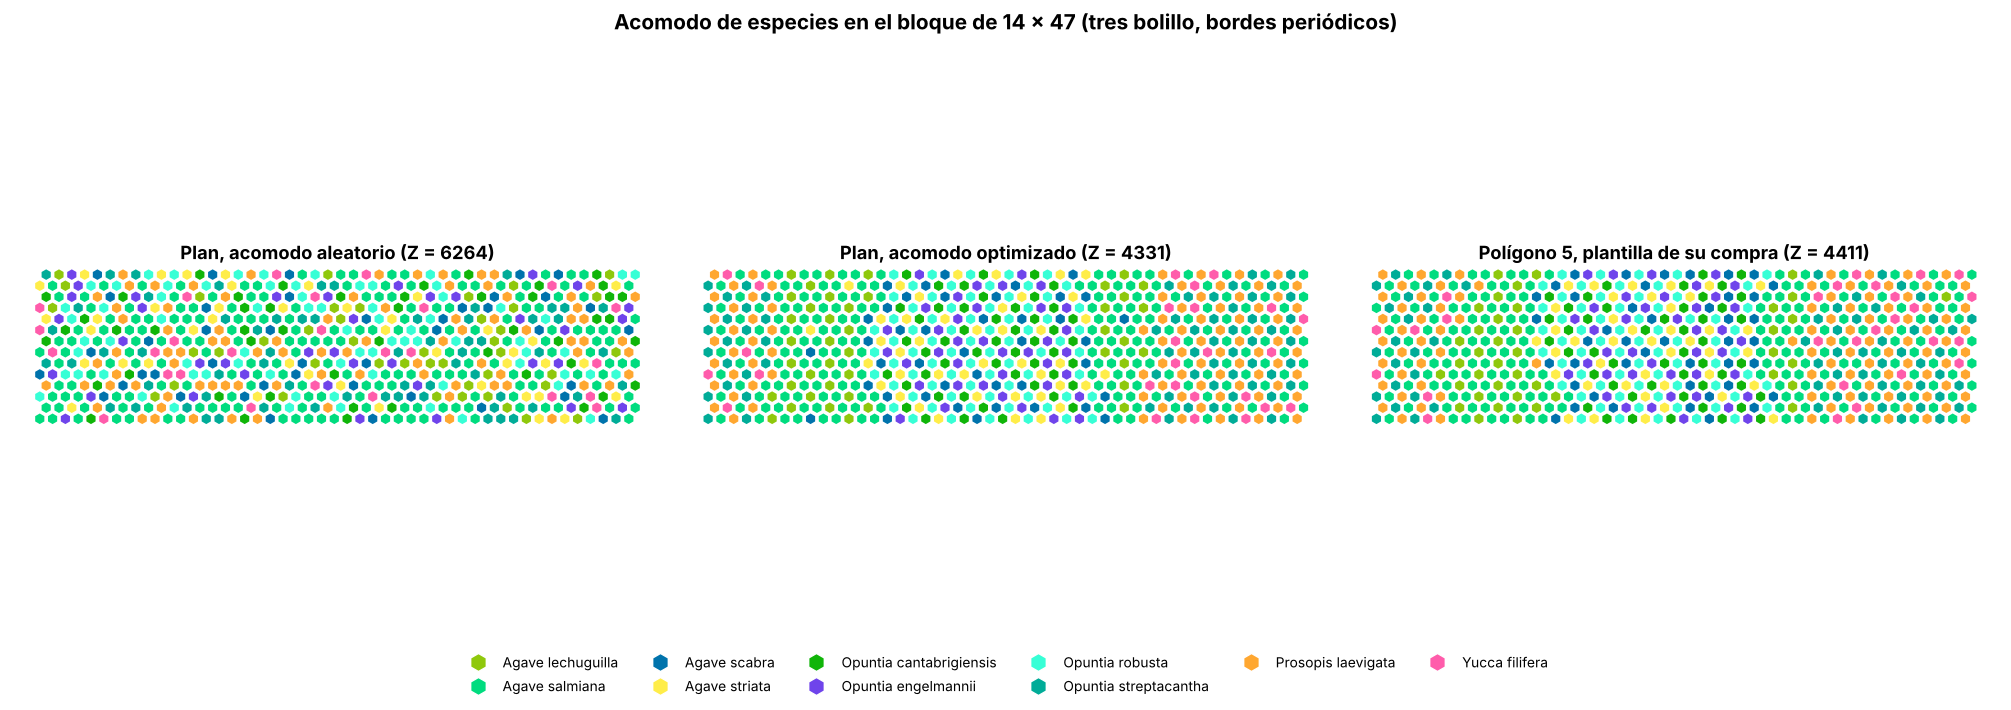

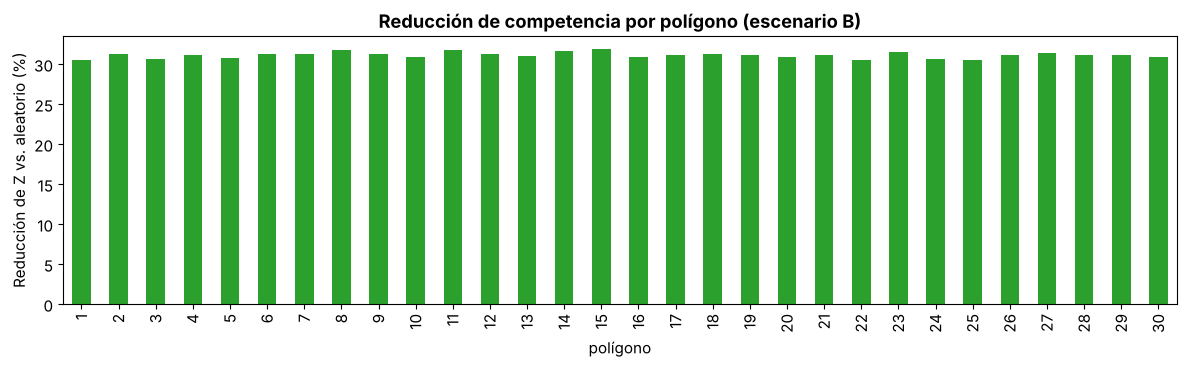

Guardados: plantillas_poligono.csv, resumen_plantillas.csv, plantilla_plan.csv, acomodo_plantillas.png


In [10]:
PALETA = ['#8fc80c', '#00dc7f', '#0073ac', '#ffed49', '#10b509', '#6f44eb', '#37ffd6', '#00ac98', '#ffa730', '#ff5cab']  # en el orden de esp
col = list(PALETA[:E_]) + ['#ededed']                                    # vacío en gris claro
etiquetas = esp + ['vacío']
coords = np.array([((k - (0.5 if r % 2 == 1 else 0.0)), r * np.sqrt(3) / 2) for r, k in pos])

def dibujar_bloque(ax, s, titulo):
    ax.scatter(coords[:, 0], coords[:, 1], c=[col[i] for i in s], marker='h', s=58, linewidths=0)
    ax.set_aspect('equal'); ax.axis('off'); ax.set_title(titulo, fontweight='bold')

pol_ej = res_pl['siembras'].idxmax()                                       # polígono con más siembras
rg = np.random.default_rng(1)
fig, axs = plt.subplots(1, 3, figsize=(20, 6.5), constrained_layout=True)
dibujar_bloque(axs[0], rg.permutation(s_plan), f'Plan, acomodo aleatorio (Z = {Zr_plan:.0f})')
dibujar_bloque(axs[1], s_plan, f'Plan, acomodo optimizado (Z = {Z_plan:.0f})')
dibujar_bloque(axs[2], plantillas[pol_ej], f'Polígono {pol_ej}, plantilla de su compra (Z = {res_pl.loc[pol_ej, "Z"]:.0f})')
usadas = sorted(set(s_plan) | set(plantillas[pol_ej]))
fig.legend(handles=[Line2D([0], [0], marker='h', color='w', markerfacecolor=col[i], markersize=13, label=etiquetas[i]) for i in usadas],
           loc='lower center', ncol=6, frameon=False, fontsize=10, bbox_to_anchor=(0.5, -0.08))
fig.suptitle('Acomodo de especies en el bloque de 14 × 47 (tres bolillo, bordes periódicos)', fontsize=15, fontweight='bold')
plt.savefig('../salidas/acomodo_plantillas.png', dpi=200, bbox_inches='tight'); plt.show()

ax = res_pl['reduccion_%'].plot.bar(figsize=(12, 3.8), color='#2ca02c')
ax.set_ylabel('Reducción de Z vs. aleatorio (%)'); ax.set_xlabel('polígono')
ax.set_title(f'Reducción de competencia por polígono (escenario {ESC_ACOMODO})', fontweight='bold'); plt.tight_layout(); plt.show()


### 5.4 Castigo por agrupamiento (para los sitios de muestreo)

CONAFOR verifica en sitios de muestreo que cubren el 5 % de la superficie. Si una especie queda agrupada, un sitio puede caer donde hay muchas o donde no hay ninguna, y la densidad estimada se aleja de la real.

Con la matriz de competencia actual, el acomodo de menor $Z$ **forma franjas**: las especies que casi no compiten entre sí (los agaves pequeños y los nopales, con $C_{ij}=0$) se juntan en una zona, y las que compiten con todas (*O. streptacantha*, *P. laevigata* y *Y. filifera*) se apartan en otra. Eso es óptimo para la competencia, pero hace que los sitios de muestreo estimen peor que con un acomodo aleatorio. Para evitarlo se minimiza

$$Z + \lambda \cdot \#\{\text{pares de la misma especie a distancia } 1 < d \le 3\},$$

donde el segundo término cuenta, para cada posición, cuántas de las 30 posiciones a 2 o 3 separaciones (además de las 6 vecinas) tienen su misma especie. $\lambda$ controla el balance: con $\lambda=0$ se obtiene el acomodo de menor competencia (5.1 y 5.2), y al subir $\lambda$ cada especie queda repartida de forma más pareja a cambio de algo más de competencia. Se usa $\lambda = 1$; el efecto se mide en 6.1. El recocido arranca de la plantilla de 5.1–5.2 y usa `numba` para que las 30 vecinas lejanas no lo hagan lento.

Con la matriz actual y $\lambda=1$, la competencia sube 11.6 % respecto al acomodo de mínima competencia, de modo que la reducción frente a un acomodo aleatorio pasa de 31.2 % a 23.2 %. A cambio, los pares de la misma especie a 2–3 separaciones bajan 68 % y desaparecen las franjas; en 6.1 se ve que el error de los sitios de muestreo queda por debajo del de un acomodo aleatorio.

In [12]:
s_plan_sin_reg = s_plan.copy(); plantillas_sin_reg = {p: s.copy() for p, s in plantillas.items()}  # copia para 6.1
LAM_REG, R_REG, ITER_REG = 1.0, 3.0, 20_000          # LAM_REG = 0 deja el acomodo de mínima competencia

def anillos(R):
    # Para cada posición, las posiciones a distancia 1 < d <= R (en separaciones) en el bloque periódico.
    W, H = NK, NF * np.sqrt(3) / 2; L = []
    for i in range(NN):
        dxy = coords - coords[i]; dxy[:, 0] -= W * np.round(dxy[:, 0] / W); dxy[:, 1] -= H * np.round(dxy[:, 1] / H)
        dist = np.hypot(*dxy.T); L.append(np.where((dist > 1.01) & (dist <= R + 0.01))[0])
    M = np.full((NN, max(map(len, L))), -1)
    for i, x in enumerate(L): M[i, :len(x)] = x
    return M

@numba.njit(cache=True)
def recocido_reg(s, C, NB, L2, lam, iters, T0, T1, seed):
    np.random.seed(seed); n = s.shape[0]; alfa = (T1 / T0) ** (1.0 / iters); T = T0
    for it in range(iters):
        p = np.random.randint(n); q = np.random.randint(n); a = s[p]; b = s[q]
        if a != b:
            dz = 0.0
            for j in NB[p]: dz += C[b, s[j]] - C[a, s[j]]
            for j in NB[q]: dz += C[a, s[j]] - C[b, s[j]]
            for j in NB[p]:
                if j == q: dz += 2 * C[a, b] - C[a, a] - C[b, b]
            dr = 0.0
            for j in L2[p]:
                if j < 0: break
                if j == q: dr -= 1.0
                elif s[j] == b: dr += 1.0
                elif s[j] == a: dr -= 1.0
            for j in L2[q]:
                if j < 0: break
                if j == p: dr -= 1.0
                elif s[j] == a: dr += 1.0
                elif s[j] == b: dr -= 1.0
            d = dz + lam * dr
            if d <= 0 or np.random.random() < np.exp(-d / T):
                s[p] = b; s[q] = a
        T *= alfa
    return s

L2 = anillos(R_REG)
pares_lejanos = lambda s: int(sum((s[i] == s[L2[i][L2[i] > i]]).sum() for i in range(NN)))

def regularizar(s, seed):
    s2 = recocido_reg(s.copy(), C, NB, L2, LAM_REG, ITER_REG * NN, 0.5, 0.005, seed)
    assert (np.bincount(s2, minlength=E_ + 1) == np.bincount(s, minlength=E_ + 1)).all()
    return s2

t0 = time.time(); filas = []
for nombre, s in [('plan', s_plan)] + list(plantillas.items()):
    s2 = regularizar(s, 1 if nombre == 'plan' else 100 + nombre)
    filas.append((nombre, costo(s), costo(s2), pares_lejanos(s), pares_lejanos(s2)))
    if nombre == 'plan': s_plan = s2
    else: plantillas[nombre] = s2
reg = pd.DataFrame(filas, columns=['plantilla', 'Z_antes', 'Z_despues', 'pares_lejanos_antes', 'pares_lejanos_despues']).set_index('plantilla')
reg['aumento_Z_%'] = 100 * (reg.Z_despues / reg.Z_antes - 1)
reg['menos_pares_%'] = 100 * (1 - reg.pares_lejanos_despues / reg.pares_lejanos_antes)
Zr_media = {p: np.mean([costo(np.random.default_rng(i).permutation(s)) for i in range(50)]) for p, s in [('plan', s_plan)] + list(plantillas.items())}
reg['reduccion_vs_aleatorio_%'] = [100 * (1 - reg.Z_despues[p] / Zr_media[p]) for p in reg.index]
print(f'{time.time()-t0:.0f} s | aumento de Z: media {reg["aumento_Z_%"].mean():.1f} %, máx {reg["aumento_Z_%"].max():.1f} % | '
      f'reducción vs aleatorio después del castigo: {reg["reduccion_vs_aleatorio_%"].mean():.1f} % | '
      f'pares lejanos de la misma especie: -{reg["menos_pares_%"].mean():.1f} % en promedio')
reg.round(3).head()

74 s | aumento de Z: media 12.0 %, máx 13.5 % | reducción vs aleatorio después del castigo: 22.9 % | pares lejanos de la misma especie: -68.8 % en promedio


,Z_antes,Z_despues,pares_lejanos_antes,pares_lejanos_despues,aumento_Z_%,menos_pares_%,reduccion_vs_aleatorio_%
plantilla,,,,,,,
plan,4330.902,4850.977,3222,1009,12.008,68.684,22.610
1,4488.363,5005.229,3154,1049,11.516,66.741,22.719
2,4361.726,4873.477,3075,991,11.733,67.772,23.177
3,4394.440,4936.785,3120,965,12.342,69.071,22.076
4,4346.471,4876.642,3086,973,12.198,68.471,22.743


### 5.5 Archivos de las plantillas
`plantillas_poligono.csv` tiene, para cada polígono, la especie de cada una de las 658 posiciones del bloque (o `vacio`), ya con el castigo de 5.4; `plantilla_plan.csv` es la plantilla del plan y `resumen_plantillas.csv` la tabla de 5.2.

In [ ]:
filas = [(pol, r, k, etiquetas[s[i]].replace('vacío', 'vacio')) for pol, s in plantillas.items() for i, (r, k) in enumerate(pos)]
pd.DataFrame(filas, columns=['poligono', 'fila', 'columna', 'especie']).to_csv('../salidas/plantillas_poligono.csv', index=False)
pd.DataFrame({'fila': [q[0] for q in pos], 'columna': [q[1] for q in pos], 'especie': [etiquetas[i] for i in s_plan]}).to_csv('../salidas/plantilla_plan.csv', index=False)
res_pl.to_csv('../salidas/resumen_plantillas.csv', index=False)
print('Guardados: plantillas_poligono.csv, plantilla_plan.csv, resumen_plantillas.csv')

## 6. Del bloque de 14 × 47 a la geometría real de cada polígono

**Polígonos.** `MapaCONAFOR.shp` (UTM 14N) se digitalizó sobre el mapa de USPAE/INECOL. Su numeración es la del mapa (1–31); `datos_limpios.csv` usa otra, y la correspondencia está en `DATOS_A_MAPA` (se obtuvo comparando áreas). Los dos pares de 8 ha (datos 21/22 = mapa 9/10 y datos 27/28 = mapa 3/4) no se distinguen por área y **se asumen en orden**. El polígono 29 del mapa (6.54 ha) no está en los datos: no tiene inventario ni compra, así que se le asigna la plantilla del plan con las proporciones de la meta.

**Malla.** Tres bolillo con 658 puntos/ha (separación de 4.19 m), con las filas paralelas al lado largo del polígono para que la cuadrilla camine en línea recta. El punto (fila $r$, columna $k$) toma la especie de la posición $((r-1)\bmod 14+1,\ (k-1)\bmod 47+1)$ de la plantilla de su polígono.

**Por qué hay que corregir.** Al repetir la plantilla sobre una forma irregular quedan bloques incompletos, y un bloque incompleto no tiene la proporción exacta de especies. En las franjas angostas (27, 20 y 12 del mapa, de unos 35 m de ancho) la malla solo usa unas pocas filas del bloque y la desviación de alguna especie llega a 20 % (polígono 20 del mapa); en los polígonos de más de 4 ha es de 2 % a 8 %.

**Conteo objetivo.** Si el polígono tiene $N_p$ puntos y se esperan $\mathbb{E}[X_p]$ plantas existentes (que la cuadrilla salta), la fracción de puntos libres es $f_p = 1-\mathbb{E}[X_p]/N_p$. Para sembrar en esperanza exactamente $q^I_{e,p}$ se necesitan $n_{e,p} = q^I_{e,p}/f_p$ posiciones de la especie $e$; el resto son vacíos. Si $\sum_e n_{e,p} > N_p$ (la compra no cabe en la malla real), todas las especies se reducen en la misma proporción y se reporta el faltante.

**Corrección.** Se cambian, una por una, posiciones de especies que sobran a especies que faltan. Cada cambio es el de menor $\Delta Z$ entre las posiciones alejadas de los cambios anteriores (distancia mínima $0.7\sqrt{\text{área}/\text{cambios}}$, que se reduce a la mitad si ya no hay candidatas), para que los cambios no se amontonen en una zona y no alteren la composición de ningún sitio de muestreo.

In [13]:
PTOS_MALLA = 658
DATOS_A_MAPA = {1: 27, 2: 28, 3: 30, 4: 20, 5: 21, 6: 22, 7: 23, 8: 24, 9: 18, 10: 17,
                11: 16, 12: 19, 13: 25, 14: 26, 15: 13, 16: 31, 17: 14, 18: 15, 19: 7, 20: 8,
                21: 9, 22: 10, 23: 11, 24: 12, 25: 6, 26: 2, 27: 3, 28: 4, 29: 5, 30: 1}
MAPA_A_DATOS = {m: d for d, m in DATOS_A_MAPA.items()}

pols = gpd.read_file('datos/mapa/MapaCONAFOR.shp')
pols['geometry'] = shapely.remove_repeated_points(pols.geometry.values, tolerance=0.01)
pols = pols.rename(columns={'poligono': 'pol_mapa'}).drop(columns=['id'], errors='ignore')
pols['pol_datos'] = pols.pol_mapa.map(MAPA_A_DATOS).astype('Int64')
pols = pols.sort_values('pol_mapa').reset_index(drop=True)

def malla(geom, ptos_ha=PTOS_MALLA):
    # Puntos de tres bolillo dentro de geom, con filas paralelas al lado largo. Devuelve fila, columna (base 1), x, y (UTM).
    a = np.sqrt(2 * 10_000 / (ptos_ha * np.sqrt(3))); h = a * np.sqrt(3) / 2
    xy = np.asarray(geom.minimum_rotated_rectangle.exterior.coords)[:3]
    l1, l2 = xy[1] - xy[0], xy[2] - xy[1]; v = l1 if np.hypot(*l1) >= np.hypot(*l2) else l2
    ang = np.degrees(np.arctan2(v[1], v[0])); c = geom.centroid
    gr = affinity.rotate(geom, -ang, origin=c); x0, y0, x1, y1 = gr.bounds; x0 -= a / 2; y0 += h / 2
    r, k = np.meshgrid(np.arange(1, int((y1 - y0) / h) + 3), np.arange(1, int((x1 - x0) / a) + 4), indexing='ij')
    xl = x0 + (k - (r % 2 == 1) * 0.5) * a; yl = y0 + (r - 1) * h          # filas impares media separación a la izquierda
    den = shapely.contains_xy(gr, xl, yl); r, k, xl, yl = r[den], k[den], xl[den], yl[den]
    t = np.radians(ang); dx, dy = xl - c.x, yl - c.y
    r0 = r.min() - 1 - (r.min() - 1) % 2                                   # renumerar desde 1 sin cambiar la paridad
    return pd.DataFrame({'fila': r - r0, 'columna': k - k.min() + 1,
                         'x': c.x + dx * np.cos(t) - dy * np.sin(t), 'y': c.y + dx * np.sin(t) + dy * np.cos(t)})

def vecinos_malla(fila, columna):
    # (n, 6): índice de cada vecina dentro del polígono, -1 si cae fuera (sin bordes periódicos).
    idx = {q: i for i, q in enumerate(zip(fila, columna))}; M = np.full((len(fila), 6), -1)
    for i, (r, k) in enumerate(zip(fila, columna)):
        v = [(r, k-1), (r, k+1), (r-1, k-1), (r-1, k), (r+1, k-1), (r+1, k)] if r % 2 == 1 else \
            [(r, k-1), (r, k+1), (r-1, k), (r-1, k+1), (r+1, k), (r+1, k+1)]
        M[i] = [idx.get(q, -1) for q in v]
    return M

def costo_malla(s, NBm):
    i, j = np.nonzero(NBm >= 0); m = NBm[i, j]; u = i < m
    return C[s[i[u]], s[m[u]]].sum()

def conteo_objetivo(n, q, ex):
    v = np.asarray(q, float) / (max(n - ex, 1e-9) / n); no_cabe = v.sum() > n
    if no_cabe: v *= n / v.sum()
    return conteo(np.r_[v, n - v.sum()], n), no_cabe

def corregir_conteos(s, w, NBm, xy):
    s = s.copy(); cnt = np.bincount(s, minlength=len(w)); nc = int(np.abs(cnt - w).sum() // 2)
    if nc == 0: return s, np.array([], int)
    d_min = 0.7 * np.sqrt(np.ptp(xy[:, 0]) * np.ptp(xy[:, 1]) / nc)
    ok = NBm >= 0; NBc = np.where(ok, NBm, 0)
    G = np.stack([(C[e, s[NBc]] * ok).sum(1) for e in range(len(w))], 1)  # G[n, e]: competencia de n si fuera e
    lejos = np.ones(len(s), bool); hechos = []
    while (cnt != w).any():
        sobra, falta = np.where(cnt > w)[0], np.where(cnt < w)[0]
        cand = np.where(np.isin(s, sobra) & lejos)[0]
        if len(cand) == 0:
            d_min /= 2; lejos[:] = True
            for n in hechos: lejos &= np.hypot(*(xy - xy[n]).T) > d_min
            continue
        dz = G[cand][:, falta] - G[cand, s[cand]][:, None]
        i, j = np.unravel_index(np.argmin(dz), dz.shape); n, e = cand[i], falta[j]; a = s[n]
        cnt[a] -= 1; cnt[e] += 1; s[n] = e; hechos.append(n)
        G[NBm[n][NBm[n] >= 0]] += C[e] - C[a]; lejos &= np.hypot(*(xy - xy[n]).T) > d_min
    return s, np.array(hechos)

mapas, filas, puntos = {}, [], []
rg = np.random.default_rng(2026); t0 = time.time()
for _, P in pols.iterrows():
    m = malla(P.geometry); NBm = vecinos_malla(m.fila.values, m.columna.values); xy = m[['x', 'y']].values; n = len(m)
    if pd.isna(P.pol_datos):
        tpl, q, ex = s_plan, w_plan[:E_] / w_plan[:E_].sum() * n, 0.0
    else:
        j = list(A.index).index(int(P.pol_datos)); tpl, q, ex = plantillas[int(P.pol_datos)], QI_ac[:, j], EXm[:, j].sum()
    w, no_cabe = conteo_objetivo(n, q, ex)
    s0 = tpl[((m.fila.values - 1) % NF) * NK + (m.columna.values - 1) % NK]   # plantilla repetida
    s1, camb = corregir_conteos(s0, w, NBm, xy)
    assert (np.bincount(s1, minlength=E_ + 1) == w).all()
    c0 = np.bincount(s0, minlength=E_ + 1)[:E_]
    Z0, Z1 = costo_malla(s0, NBm), costo_malla(s1, NBm)
    Zr = np.mean([costo_malla(rg.permutation(s1), NBm) for _ in range(20)])
    filas.append(dict(pol_mapa=P.pol_mapa, pol_datos=P.pol_datos, area_mapa=P.area_map, area_shp=P.geometry.area / 1e4,
                      puntos=n, existentes_esp=ex, siembra_compra=q.sum() if not pd.isna(P.pol_datos) else np.nan,
                      no_cabe=no_cabe, faltante=max(0.0, q.sum() - (n - ex)) if not pd.isna(P.pol_datos) else 0.0,
                      vacios=w[VACIO], cambios=len(camb), cambios_pct=100 * len(camb) / n,
                      desv_max_sin_corregir_pct=100 * (np.abs(c0 - w[:E_]) / np.maximum(w[:E_], 1)).max(),
                      Z_repetida=Z0, Z_corregida=Z1, reduccion_vs_aleatorio_pct=100 * (1 - Z1 / Zr)))
    mapas[P.pol_mapa] = dict(m=m, s0=s0, s1=s1, w=w, geom=P.geometry, NBm=NBm)
    puntos.append(m.assign(pol_mapa=P.pol_mapa, pol_datos=P.pol_datos, especie=[etiquetas[i] for i in s1],
                           cambiado=np.isin(np.arange(n), camb)))
res_mapa = pd.DataFrame(filas).set_index('pol_mapa')
print(f'{time.time()-t0:.0f} s | {res_mapa.puntos.sum():,} puntos | cambios: {res_mapa.cambios.sum():,} '
      f'({100*res_mapa.cambios.sum()/res_mapa.puntos.sum():.2f} %) | desviación máxima sin corregir: '
      f'{res_mapa.desv_max_sin_corregir_pct.max():.1f} % | faltante por falta de puntos: {res_mapa.faltante.sum():,.0f} plantas '
      f'en {int(res_mapa.no_cabe.sum())} polígonos | vacíos extra: {res_mapa.vacios.sum():,}')
res_mapa.round(2)

1 s | 124,477 puntos | cambios: 1,485 (1.19 %) | desviación máxima sin corregir: 25.9 % | faltante por falta de puntos: 1,000 plantas en 15 polígonos | vacíos extra: 981


,pol_datos,area_mapa,area_shp,puntos,existentes_esp,siembra_compra,no_cabe,faltante,vacios,cambios,cambios_pct,desv_max_sin_corregir_pct,Z_repetida,Z_corregida,reduccion_vs_aleatorio_pct
pol_mapa,,,,,,,,,,,,,,,
1,30,5.40,5.12,3406,671.71,2881.0,True,146.71,0,19,0.56,2.49,24649.79,24692.98,22.47
2,26,7.52,7.37,4847,943.39,4004.0,True,100.39,0,27,0.56,3.11,35635.54,35533.79,22.75
3,27,8.00,8.17,5365,989.91,4274.0,False,0.00,124,124,2.31,4.22,39179.52,36534.20,24.52
4,28,8.00,8.10,5356,993.69,4270.0,False,0.00,113,117,2.18,4.23,39002.22,36810.96,24.29
5,29,7.56,7.30,4790,914.83,4059.0,True,183.83,0,25,0.52,2.60,34792.87,34582.41,23.48
6,25,4.19,4.20,2760,515.91,2241.0,False,0.00,4,25,0.91,2.36,20012.33,19996.23,23.01
7,19,6.28,6.27,4096,771.51,3360.0,True,35.51,0,28,0.68,8.77,29026.51,29091.44,23.01
8,20,7.60,7.58,4970,927.33,4073.0,True,30.33,0,41,0.82,2.79,36898.57,36821.51,22.61
9,21,8.00,8.05,5261,986.04,4277.0,True,2.04,0,22,0.42,3.17,38184.80,38053.57,23.32


### 6.1 Verificación con sitios de muestreo

No sabemos dónde ni de qué tamaño son los sitios; solo que cubren el 5 % de la superficie. Se simulan sitios circulares de 400 m² colocados al azar dentro de cada polígono (sin traslaparse y completamente adentro) y, para cada especie, se compara la densidad que estimarían con la densidad real del mapa. Se comparan tres acomodos con los mismos conteos: aleatorio, la plantilla de mínima competencia ($\lambda=0$) y la plantilla con el castigo por agrupamiento de 5.4 ($\lambda=1$), las dos con los conteos corregidos. Las plantas existentes no se incluyen porque no se conoce su ubicación.

In [14]:
SITIO_M2, N_SIM = 400, 300
rg = np.random.default_rng(7)

def centros_sitios(geom, area_s=SITIO_M2, frac=0.05):
    r = np.sqrt(area_s / np.pi); nec = max(1, round(frac * geom.area / area_s)); ad = geom.buffer(-r)
    ad = geom if ad.is_empty else ad; x0, y0, x1, y1 = ad.bounds; cs = []
    for _ in range(20_000):
        if len(cs) == nec: break
        p = rg.uniform([x0, y0], [x1, y1])
        if shapely.contains_xy(ad, *p) and all(np.hypot(*(p - c)) >= 2 * r for c in cs): cs.append(p)
    return np.array(cs), r

# Mapas con las plantillas de mínima competencia (5.2, sin castigo) para comparar
s_sin_reg = {}
for pol, M in mapas.items():
    pdat = pols.set_index('pol_mapa').pol_datos[pol]
    tpl0 = s_plan_sin_reg if pd.isna(pdat) else plantillas_sin_reg[int(pdat)]
    m = M['m']; s0 = tpl0[((m.fila.values - 1) % NF) * NK + (m.columna.values - 1) % NK]
    s_sin_reg[pol], _ = corregir_conteos(s0, M['w'], M['NBm'], m[['x', 'y']].values)

filas = []
for pol, M in mapas.items():
    xy = M['m'][['x', 'y']].values; tree = cKDTree(xy); w = M['w']
    for _ in range(N_SIM):
        cs, r = centros_sitios(M['geom']); idx = np.concatenate(tree.query_ball_point(cs, r)).astype(int)
        frac = len(cs) * SITIO_M2 / M['geom'].area
        for nombre, s in (('aleatorio', rg.permutation(M['s1'])), ('mínima competencia', s_sin_reg[pol]), ('con castigo', M['s1'])):
            est = np.bincount(s[idx], minlength=E_ + 1)[:E_] / frac
            filas += [(pol, nombre, esp[e], est[e] / w[e] - 1) for e in range(E_) if w[e] > 0]
sit = pd.DataFrame(filas, columns=['pol_mapa', 'acomodo', 'especie', 'err_rel'])
orden = ['aleatorio', 'mínima competencia', 'con castigo']
tab = pd.concat({'desv. est. del error (%)': sit.groupby(['especie', 'acomodo']).err_rel.std().unstack()[orden] * 100,
                 'P(estimación < 80 % de la real) (%)': (sit.assign(b=sit.err_rel < -0.2).groupby(['especie', 'acomodo']).b.mean().unstack()[orden] * 100)}, axis=1)
tab.round(1)

desv. est. del error (%)                     \
acomodo                                aleatorio mínima competencia   
especie                                                               
Agave lechuguilla                           30.1               57.6   
Agave salmiana                              12.2               28.9   
Agave scabra                                28.8               44.9   
Agave striata                               30.0               45.7   
Opuntia cantabrigiensis                     26.6               49.0   
Opuntia engelmannii                         31.2               49.4   
Opuntia robusta                             22.6               45.9   
Opuntia streptacantha                       22.9               41.0   
Prosopis laevigata                          19.1               37.9   
Yucca filifera                              36.8               49.0   

                                    P(estimación < 80 % de la real) (%)  \
acomodo                 con castigo                           aleatorio   
especie                                                                   
Agave lechuguilla              20.4                                23.3   
Agave salmiana                  7.2                                 4.7   
Agave scabra                   19.9                                23.5   
Agave striata                  21.4                                24.9   
Opuntia cantabrigiensis        19.0                                20.6   
Opuntia engelmannii            23.7                                25.2   
Opuntia robusta                14.2                                17.2   
Opuntia streptacantha          19.3                                17.5   
Prosopis laevigata             13.0                                13.6   
Yucca filifera                 36.3                                29.1   

                                                        
acomodo                 mínima competencia con castigo  
especie                                                 
Agave lechuguilla                     35.7        13.2  
Agave salmiana                        24.4         1.2  
Agave scabra                          29.5        15.0  
Agave striata                         29.5        15.7  
Opuntia cantabrigiensis               32.1        11.3  
Opuntia engelmannii                   32.9        17.3  
Opuntia robusta                       29.6         7.2  
Opuntia streptacantha                 35.3        12.6  
Prosopis laevigata                    35.9         6.5  
Yucca filifera                        36.8        26.7

### 6.2 Mapas y archivos para campo
`mapa_siembra.gpkg` tiene dos capas: `poligonos` y `puntos` (cada punto de la malla con polígono, fila, columna, especie y si es una de las posiciones cambiadas). Se puede abrir en QGIS o cargar en un GPS. `mapa_siembra_puntos.csv` tiene lo mismo con coordenadas UTM y geográficas.

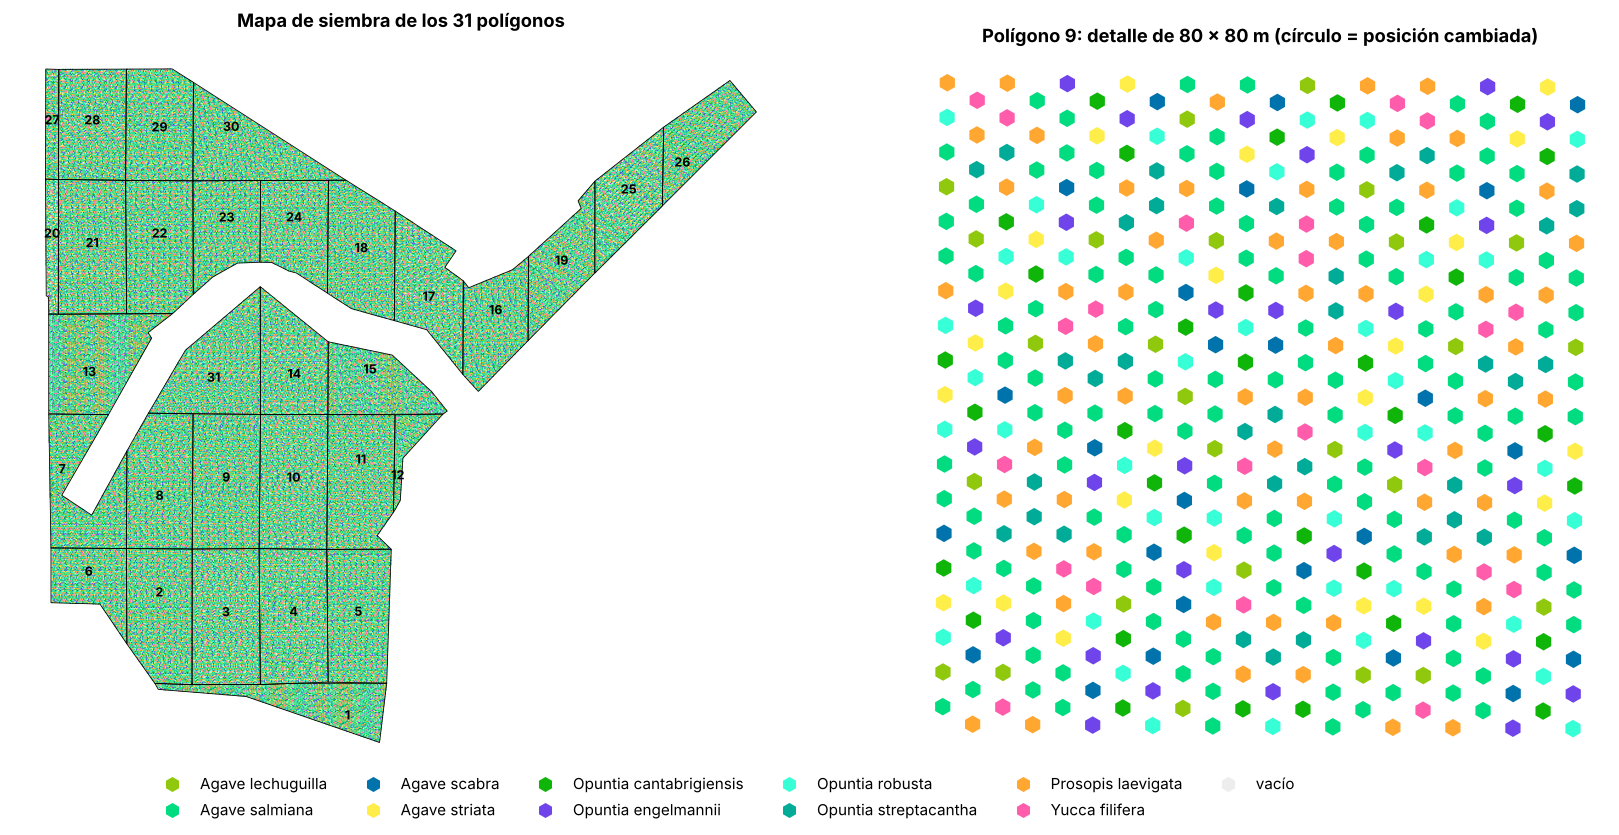

Guardados: mapa_siembra.gpkg, mapa_siembra_puntos.csv, resumen_mapas.csv, mapa_siembra.png, plantillas_poligono.csv, plantilla_plan.csv


In [15]:
fig, axs = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw=dict(width_ratios=[1.6, 1]))
for pol, M in mapas.items():
    m = M['m']; axs[0].scatter(m.x, m.y, c=[col[i] for i in M['s1']], s=1.2, linewidths=0, rasterized=True)
pols.boundary.plot(ax=axs[0], color='k', lw=0.6)
for _, P in pols.iterrows():
    pt = P.geometry.representative_point(); axs[0].text(pt.x, pt.y, P.pol_mapa, fontsize=9, ha='center', weight='bold')
axs[0].set_aspect('equal'); axs[0].set_axis_off(); axs[0].set_title('Mapa de siembra de los 31 polígonos', fontweight='bold')
M = mapas[9]; m = M['m']; x0, y0 = M['geom'].centroid.coords[0]
sel = (np.abs(m.x - x0) < 40) & (np.abs(m.y - y0) < 40)
axs[1].scatter(m.x[sel], m.y[sel], c=[col[i] for i in M['s1'][sel.values]], s=160, marker='h', linewidths=0)
ch = sel.values & np.isin(np.arange(len(m)), np.where(M['s1'] != M['s0'])[0])
axs[1].scatter(m.x[ch], m.y[ch], s=260, facecolors='none', edgecolors='k', linewidths=1.5)
axs[1].set_aspect('equal'); axs[1].set_axis_off(); axs[1].set_title('Polígono 9: detalle de 80 × 80 m (círculo = posición cambiada)', fontweight='bold')
fig.legend(handles=[Line2D([0], [0], marker='h', color='w', markerfacecolor=col[i], markersize=12, label=etiquetas[i]) for i in range(E_ + 1)],
           loc='lower center', ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.05))
plt.tight_layout(); plt.savefig('../salidas/mapa_siembra.png', dpi=200, bbox_inches='tight'); plt.show()

pts = pd.concat(puntos, ignore_index=True)
gp = gpd.GeoDataFrame(pts, geometry=gpd.points_from_xy(pts.x, pts.y), crs=pols.crs)
ll = gp.to_crs(4326); gp['lon'], gp['lat'] = ll.geometry.x.round(7), ll.geometry.y.round(7)
gp['x'], gp['y'] = gp.x.round(2), gp.y.round(2)
gp[['pol_mapa', 'pol_datos', 'fila', 'columna', 'especie', 'cambiado', 'x', 'y', 'lon', 'lat']].to_csv('../salidas/mapa_siembra_puntos.csv', index=False)
gp.to_file('../salidas/mapa_siembra.gpkg', layer='puntos', driver='GPKG'); pols.to_file('../salidas/mapa_siembra.gpkg', layer='poligonos', driver='GPKG')
res_mapa.to_csv('../salidas/resumen_mapas.csv')
print('Guardados: mapa_siembra.gpkg, mapa_siembra_puntos.csv, resumen_mapas.csv, mapa_siembra.png')

## 7. ¿Qué se pierde con una sola plantilla repetida en todo el terreno?

El socio formador prefiere un patrón que se repita en todo el terreno a un mapa completo por polígono. Aquí se comparan cuatro formas de plantar, todas sobre la malla real de los 30 polígonos con datos (el 29 del mapa no tiene inventario y se excluye):

| Método | Qué se siembra en cada punto libre | Reposición |
|---|---|---|
| **Mapa completo** (secciones 1–6) | La plantilla de su polígono, con los conteos corregidos para que coincidan con la compra | Las $q^R_{e,p}$ compradas |
| **Plantilla por polígono** | La plantilla de su polígono (5.2–5.4) repetida, sin corregir | Las $q^R_{e,p}$ compradas |
| **Plantilla única, mismo presupuesto** | La plantilla del plan (5.1–5.4) repetida en todos los polígonos, sin corregir | Con el dinero que sobra después de sembrar, se reponen plantas muertas al azar hasta que se acaba |
| **Plantilla única, reponer todo** | Igual | Se repone cada planta muerta (una vez), cueste lo que cueste |

**Cómo se simula.** En cada uno de 2,000 escenarios: (i) se sortean las plantas existentes $X_{e,p}\sim\text{Bin}(x_{e,p},0.95)$ y, como no se sabe dónde están, ocupan $\sum_e X_{e,p}$ puntos elegidos al azar de la malla real (los mismos puntos para los cuatro métodos); (ii) en los puntos libres se siembra lo que indica cada método; (iii) cada planta se establece con probabilidad $S_e$, y las muertas se reponen según la regla del método, con la misma especie y la misma probabilidad de establecerse.

**Costo.** Se cuentan las plantas que realmente se usan: para el mapa completo y la plantilla por polígono, las siembras más las $q^R$ compradas; para la plantilla única, las siembras más las reposiciones hechas. El presupuesto es el del escenario `ESC_ACOMODO` para los 30 polígonos.

In [16]:
N_COMP, SEED_COMP = 2000, 31
METODOS = ['Mapa completo', 'Plantilla por polígono', 'Plantilla única, mismo presupuesto', 'Plantilla única, reponer todo']
pol_datos_a_mapa = {int(r.pol_datos): int(r.pol_mapa) for _, r in pols.dropna(subset=['pol_datos']).iterrows()}

rgc = np.random.default_rng(SEED_COMP)
Xc = rgc.binomial(x.values, 1 - ERR_REG, size=(N_COMP, E_, P_))            # plantas existentes por escenario
sembradas = {m: np.zeros((N_COMP, E_, P_), np.int32) for m in METODOS[:3]}  # plantas sembradas (1a siembra)
t0 = time.time()
for p, pol in enumerate(A.index):
    M = mapas[pol_datos_a_mapa[pol]]; m = M['m']; n = len(m)
    asign = {'Mapa completo': M['s1'], 'Plantilla por polígono': M['s0'],
             'Plantilla única, mismo presupuesto': s_plan[((m.fila.values - 1) % NF) * NK + (m.columna.values - 1) % NK]}
    ocup = np.minimum(Xc[:, :, p].sum(1), n)                                 # puntos ocupados por existentes
    rango = np.argsort(rgc.random((N_COMP, n)), axis=1).argsort(axis=1)      # orden aleatorio de los puntos
    libre = rango >= ocup[:, None]                                          # (N_COMP, n): punto libre
    for nombre, s in asign.items():
        for e in range(E_):
            sembradas[nombre][:, e, p] = libre[:, s == e].sum(1)
sembradas['Plantilla única, reponer todo'] = sembradas['Plantilla única, mismo presupuesto']
print(f'{time.time()-t0:.0f} s')

9 s


In [17]:
def evaluar(nombre, QR=None, phi=None):
    # phi: fracción de muertas que se repone (plantilla única); None + QR: reposición comprada (hasta q^R por especie).
    r = np.random.default_rng(SEED_COMP + 1)                                # mismos sorteos de supervivencia para todos
    Q = sembradas[nombre]
    ZI = r.binomial(Q, S[None, :, None]); muertas = Q - ZI
    if QR is not None:
        R = np.minimum(QR[None], muertas); costo_rep = (c[:, None] * QR).sum() * np.ones(N_COMP)
    else:
        R = r.binomial(muertas, phi[:, None, None]) if np.ndim(phi) else r.binomial(muertas, phi)
        costo_rep = (c[None, :, None] * R).sum((1, 2))
    ZR = r.binomial(R, S[None, :, None])
    F1 = np.maximum(0, D - Xc - Q); F2 = np.maximum(0, D - Xc - ZI - ZR)
    costo_total = (c[None, :, None] * Q).sum((1, 2)) + costo_rep
    return dict(Q=Q, F1=F1, F2=F2, costo=costo_total, muertas=muertas)

presup_total = B_ha_ac * A.sum()
res_c = {'Mapa completo': evaluar('Mapa completo', QR=QR_ac),
         'Plantilla por polígono': evaluar('Plantilla por polígono', QR=QR_ac)}
# Plantilla única, mismo presupuesto: se repone una fracción phi de las muertas con lo que sobra tras sembrar
Q_u = sembradas['Plantilla única, mismo presupuesto']
r_tmp = np.random.default_rng(SEED_COMP + 1); muertas_u = Q_u - r_tmp.binomial(Q_u, S[None, :, None])
sobra = presup_total - (c[None, :, None] * Q_u).sum((1, 2))
phi_u = np.clip(sobra / np.maximum((c[None, :, None] * muertas_u).sum((1, 2)), 1), 0, 1)
res_c['Plantilla única, mismo presupuesto'] = evaluar('Plantilla única, mismo presupuesto', phi=phi_u)
res_c['Plantilla única, reponer todo'] = evaluar('Plantilla única, reponer todo', phi=1.0)

filas = []
for nombre, R_ in res_c.items():
    F2pe = R_['F2'].mean(0)                                                 # (E, P)
    filas.append({'método': nombre,
                  'siembras': R_['Q'].sum((1, 2)).mean(),
                  'faltante_1a_siembra_%': 100 * R_['F1'].sum((1, 2)).mean() / D.sum(),
                  'faltante_2_anios_%': 100 * R_['F2'].sum((1, 2)).mean() / D.sum(),
                  'faltante_2_anios_plantas': R_['F2'].sum((1, 2)).mean(),
                  'peor_especie_%': 100 * (F2pe.sum(1) / D.sum(1)).max(),
                  'peor_especie_poligono_%': 100 * (F2pe / D).max(),
                  'costo_total': R_['costo'].mean(), 'costo_ha': R_['costo'].mean() / A.sum(),
                  'sobre_presupuesto': R_['costo'].mean() - presup_total})
comp_metodos = pd.DataFrame(filas).set_index('método')
print(f'Presupuesto del escenario {ESC_ACOMODO}: ${presup_total:,.0f} (${B_ha_ac:,}/ha) | '
      f'en la plantilla única se repone en promedio el {100*phi_u.mean():.0f} % de las muertas con lo que sobra')
comp_metodos.round({'siembras': 0, 'faltante_1a_siembra_%': 2, 'faltante_2_anios_%': 2, 'faltante_2_anios_plantas': 0,
                    'peor_especie_%': 1, 'peor_especie_poligono_%': 1, 'costo_total': 0, 'costo_ha': 0, 'sobre_presupuesto': 0})

Presupuesto del escenario B: $2,415,732 ($13,200/ha) | en la plantilla única se repone en promedio el 37 % de las muertas con lo que sobra


,siembras,faltante_1a_siembra_%,faltante_2_anios_%,faltante_2_anios_plantas,peor_especie_%,peor_especie_poligono_%,costo_total,costo_ha,sobre_presupuesto
método,,,,,,,,,
Mapa completo,97017.0,2.32,8.81,10613.0,8.9,11.7,2392231.0,13072.0,-23501.0
Plantilla por polígono,97819.0,2.05,8.26,9952.0,8.6,15.7,2411787.0,13178.0,-3945.0
"Plantilla única, mismo presupuesto",97819.0,1.45,7.80,9398.0,18.5,28.5,2415712.0,13200.0,-20.0
"Plantilla única, reponer todo",97819.0,1.45,2.64,3173.0,8.8,19.2,2611723.0,14271.0,195991.0


**Faltante por especie a los dos años.** La plantilla única siembra cada especie en la proporción de la meta, sin tomar en cuenta qué especies sobreviven peor ni cuántas plantas existentes hay de cada una; el mapa y la plantilla por polígono sí, porque vienen de la compra optimizada.

,Mapa completo,Plantilla por polígono,"Plantilla única, mismo presupuesto","Plantilla única, reponer todo"
Agave lechuguilla,8.7,7.7,4.6,2.2
Agave salmiana,8.9,8.3,5.1,1.4
Agave scabra,8.7,7.9,16.1,6.5
Agave striata,8.8,8.3,5.1,2.0
Opuntia cantabrigiensis,8.8,8.5,9.6,3.3
Opuntia engelmannii,8.7,8.2,9.7,2.9
Opuntia robusta,8.8,8.5,4.2,1.2
Opuntia streptacantha,8.8,8.4,8.3,2.6
Prosopis laevigata,8.8,8.1,10.4,3.0
Yucca filifera,8.6,8.6,18.5,8.8


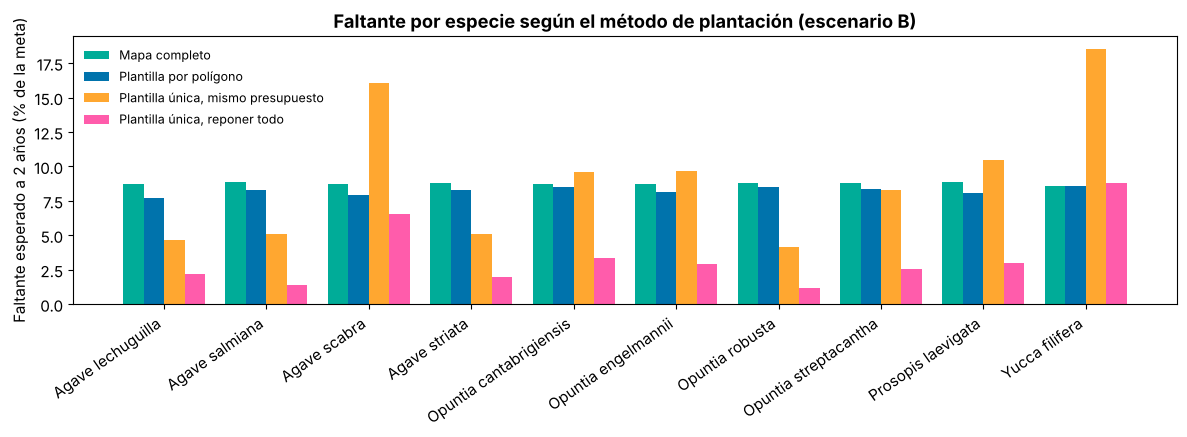

In [18]:
t_esp_c = pd.DataFrame({k: 100 * v['F2'].mean(0).sum(1) / D.sum(1) for k, v in res_c.items()}, index=esp)
display(t_esp_c.round(1))
fig, ax = plt.subplots(figsize=(12, 4.5)); w_bar = 0.2; i = np.arange(E_)
for j, (k, colr) in enumerate(zip(METODOS, ['#00ac98', '#0073ac', '#ffa730', '#ff5cab'])):
    ax.bar(i + (j - 1.5) * w_bar, t_esp_c[k], w_bar, label=k, color=colr)
ax.set_xticks(i, esp, rotation=35, ha='right'); ax.set_ylabel('Faltante esperado a 2 años (% de la meta)')
ax.set_title(f'Faltante por especie según el método de plantación (escenario {ESC_ACOMODO})', fontweight='bold')
ax.legend(frameon=False, fontsize=9); plt.tight_layout(); plt.savefig('../salidas/comparacion_metodos.png', dpi=200, bbox_inches='tight'); plt.show()

**Ojo con el faltante total.** La compra usa el criterio *equilibrado*: reparte el faltante por igual entre especies (todas quedan cerca de 8.8 %) en lugar de minimizar el total. La plantilla única, en cambio, siembra en la proporción de la meta y repone al azar, así que el dinero rinde más en las especies baratas y de alta supervivencia (*O. robusta*, *A. lechuguilla*) y se queda corto en las caras y de baja supervivencia (*A. scabra*, *Y. filifera*). Por eso su faltante **total** puede salir menor, pero con especies muy por debajo de su meta. Como CONAFOR verifica por especie, la comparación justa es la **peor especie**.

**¿Cuánto más cuesta la plantilla única para quedar igual que el mapa?** Con la plantilla única, el único margen es reponer más plantas muertas. La celda siguiente sube la fracción de muertas que se repone, de 0 a 100 %, y busca el presupuesto con el que la peor especie queda igual que en el mapa completo (y, como referencia, el presupuesto con el que se iguala el faltante total).

,valor del mapa completo (%),costo plantilla única,costo/ha,extra vs presupuesto,extra %
criterio,,,,,
peor especie,8.9,2609356.5,14258.0,193624.5,8.0
faltante total,8.8,2380817.8,13009.2,-34914.2,-1.4


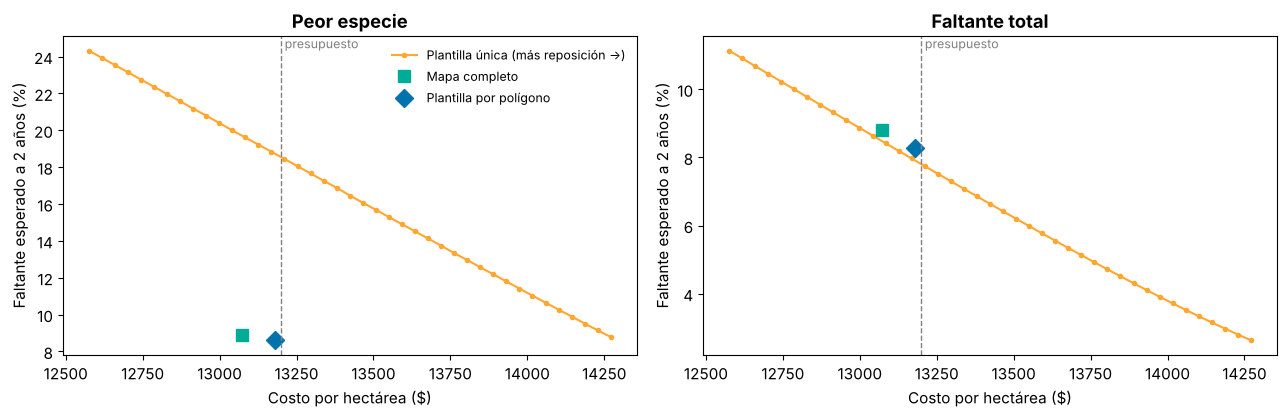

,fraccion_repuesta,costo,faltante_total_%,peor_especie_%,costo_ha
0,0.0,2301351.0,11.14,24.3,12575.0
4,0.1,2332365.0,10.23,22.8,12744.0
8,0.2,2363398.0,9.32,21.2,12914.0
12,0.3,2394420.0,8.42,19.6,13084.0
16,0.4,2425522.0,7.52,18.1,13253.0
20,0.5,2456540.0,6.64,16.5,13423.0
24,0.6,2487573.0,5.77,14.9,13593.0
28,0.7,2518608.0,4.92,13.3,13762.0
32,0.8,2549676.0,4.11,11.8,13932.0
36,0.9,2580709.0,3.34,10.3,14101.0


In [19]:
curva = []
for phi in np.linspace(0, 1, 41):
    R_ = evaluar('Plantilla única, mismo presupuesto', phi=phi)
    curva.append((phi, R_['costo'].mean(), 100 * R_['F2'].sum((1, 2)).mean() / D.sum(), 100 * (R_['F2'].mean(0).sum(1) / D.sum(1)).max()))
curva = pd.DataFrame(curva, columns=['fraccion_repuesta', 'costo', 'faltante_total_%', 'peor_especie_%'])
curva['costo_ha'] = curva.costo / A.sum()

def costo_para(col, obj):
    # Interpola el costo con el que la columna `col` de la curva baja a `obj`; None si no se alcanza.
    ok = curva[curva[col] <= obj]
    if not len(ok): return None
    i1 = ok.index[0]; i0 = max(i1 - 1, 0); a0, a1 = curva.loc[i0], curva.loc[i1]
    t = 0 if i1 == i0 else (a0[col] - obj) / (a0[col] - a1[col])
    return a0.costo + t * (a1.costo - a0.costo)

filas = []
for col, met in (('peor_especie_%', 'peor_especie_%'), ('faltante_total_%', 'faltante_2_anios_%')):
    obj = comp_metodos.loc['Mapa completo', met]; cst = costo_para(col, obj)
    filas.append({'criterio': 'peor especie' if col == 'peor_especie_%' else 'faltante total', 'valor del mapa completo (%)': obj,
                  'costo plantilla única': cst, 'costo/ha': None if cst is None else cst / A.sum(),
                  'extra vs presupuesto': None if cst is None else cst - presup_total,
                  'extra %': None if cst is None else 100 * (cst / presup_total - 1)})
igualar = pd.DataFrame(filas).set_index('criterio')
display(igualar.round(1))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, col, met, tit in ((axs[0], 'peor_especie_%', 'peor_especie_%', 'Peor especie'), (axs[1], 'faltante_total_%', 'faltante_2_anios_%', 'Faltante total')):
    ax.plot(curva.costo_ha, curva[col], '-o', color='#ffa730', ms=3, label='Plantilla única (más reposición →)')
    for k, mk, colr in (('Mapa completo', 's', '#00ac98'), ('Plantilla por polígono', 'D', '#0073ac')):
        ax.plot(comp_metodos.loc[k, 'costo_ha'], comp_metodos.loc[k, met], mk, ms=9, color=colr, label=k)
    ax.axvline(B_ha_ac, color='grey', ls='--', lw=1); ax.text(B_ha_ac, ax.get_ylim()[1], ' presupuesto', va='top', fontsize=9, color='grey')
    ax.set_xlabel('Costo por hectárea ($)'); ax.set_ylabel('Faltante esperado a 2 años (%)'); ax.set_title(tit, fontweight='bold')
axs[0].legend(frameon=False, fontsize=9); plt.tight_layout(); plt.savefig('../salidas/costo_vs_faltante.png', dpi=200, bbox_inches='tight'); plt.show()
curva.iloc[::4].round({'fraccion_repuesta': 2, 'costo': 0, 'faltante_total_%': 2, 'peor_especie_%': 1, 'costo_ha': 0})

**Polígonos donde más se nota.** En las franjas angostas la plantilla repetida sin corregir solo usa unas pocas filas del bloque, así que algunas especies quedan muy por arriba o muy por debajo de su meta.

In [20]:
pp = pd.DataFrame({k: 100 * v['F2'].mean(0).sum(0) / D.sum(0) for k, v in res_c.items()}, index=A.index)
pp['peor_especie_plantilla_unica_%'] = 100 * (res_c['Plantilla única, mismo presupuesto']['F2'].mean(0) / D).max(0)
pp['peor_especie_mapa_%'] = 100 * (res_c['Mapa completo']['F2'].mean(0) / D).max(0)
pp.index = [f'{p} (mapa {pol_datos_a_mapa[p]})' for p in A.index]; pp.index.name = 'polígono datos (mapa)'
comp_metodos.to_csv('../salidas/comparacion_metodos.csv'); pp.to_csv('../salidas/comparacion_metodos_poligono.csv')
pp.round(1).sort_values('peor_especie_plantilla_unica_%', ascending=False).head(10)

,Mapa completo,Plantilla por polígono,"Plantilla única, mismo presupuesto","Plantilla única, reponer todo",peor_especie_plantilla_unica_%,peor_especie_mapa_%
polígono datos (mapa),,,,,,
20 (mapa 8),8.9,8.9,8.2,3.0,28.5,8.9
26 (mapa 2),9.4,9.4,9.4,3.9,25.9,9.6
3 (mapa 30),10.0,9.9,9.3,3.8,24.2,10.1
18 (mapa 15),9.7,9.8,8.5,3.1,23.8,9.9
29 (mapa 5),11.4,11.4,11.0,5.4,23.7,11.7
11 (mapa 16),11.2,11.3,10.9,5.4,22.7,11.5
12 (mapa 19),8.5,8.0,7.1,2.0,22.5,8.7
30 (mapa 1),11.3,11.4,11.3,5.9,22.3,11.6
19 (mapa 7),8.7,8.6,8.4,2.9,21.3,8.8
